In [1]:
# NB-11: Regresión, Gradiente y Regularización
# Generado para: Andrés Hormazábal — UDP
# Parte del sistema de 25 notebooks de estudio ML/IA
# Fecha de generación: 2026-10-30

# NB-11: Regresión, Gradiente y Regularización

**Bloque:** 3 — Aprendizaje supervisado

**Base bibliográfica:** Géron, *Hands-On ML* (cap. 4: modelos lineales, gradiente,
regularización; cap. 2: curvas de aprendizaje) · Raschka, *ML with PyTorch and
Scikit-Learn* (cap. 3: regresión logística y regularización; cap. 4: escalado) ·
VanderPlas, *Python Data Science Handbook* (cap. 42: regresión lineal) · Hastie,
Tibshirani & Friedman, *ESL* (cap. 3) para la geometría de Ridge y Lasso

**Prerequisitos:** NB-03 es el prerrequisito duro, y se retoma literalmente:
**§3.3** (mínimos cuadrados como proyección, QR), **§3.4** (número de condición),
**§5.3** (pseudoinversa y regularización por SVD), **§7.1–7.2** (descenso de gradiente
y *gradient checking*). De NB-01, `pandas` y gráficos.

## Objetivos de Aprendizaje

Al completar este notebook serás capaz de:

1. **Resolver** una regresión lineal por tres caminos (ecuación normal, factorización
   QR/SVD, descenso de gradiente) y **justificar cuál usar** según el condicionamiento.
2. **Diagnosticar** sobreajuste y subajuste con **curvas de aprendizaje**, en vez de
   mirar solo el error de entrenamiento.
3. **Explicar y demostrar** por qué **L1 (Lasso) produce coeficientes exactamente cero**
   y **L2 (Ridge) no**, con el argumento geométrico.
4. **Elegir** el hiperparámetro de regularización con **validación cruzada**, no a ojo.
5. **Derivar** la regresión logística desde la lineal y explicar por qué su pérdida es
   la **entropía cruzada** y no el error cuadrático.
6. **Evitar** los tres errores que invalidan un experimento: no escalar, usar el test
   para elegir, y filtrar antes de partir.

| Curso / Área | Relevancia |
|---|---|
| **IA (CIT-2013)** | **Control 4 (~9 nov): "Regularización" y "ANN"**. La regularización es este notebook completo; las ANN se construyen sobre el gradiente de §4. **Control 3** ya cubrió regresión lineal y logística: esto también sirve para la Solemne 2. |
| Big Data (CIT-2309) | El escalado y la fuga de datos son los errores que arruinan un pipeline de ETL→modelo. La regularización es el mismo principio que la penalización por complejidad en cualquier ranking. |
| Sistemas Distribuidos (CIT-2011) | El descenso de gradiente es el algoritmo que se paraleliza en todo entrenamiento distribuido: *data parallelism* promedia gradientes entre nodos. Entender por qué el gradiente es una **suma sobre muestras** (§4) es entender por qué se puede repartir. |
| Comunicaciones Digitales (CIT-2111) | El ecualizador FIR por mínimos cuadrados de NB-03 §Nivel 3 **es** una regresión lineal; añadirle `λI` fue aplicar Ridge sin llamarlo así. |
| Tesis SNN/Ojo | Predecir BER a partir de métricas de diagrama de ojo es una regresión: §6 da la regularización para cuando tengas más métricas que experimentos, y §8 el protocolo para no engañarte con fuga de datos. |
| Notebooks relacionados | NB-03 (base matemática), NB-10 (métricas de clasificación), NB-14 (PCA), NB-16 (backpropagation: el gradiente de §4 encadenado), NB-17 (Adam) |

## Tabla de contenidos

1. Marco teórico: qué significa "aprender" una función
2. Configuración
3. Regresión lineal: tres caminos al mismo sitio
4. Descenso de gradiente
5. El sobreajuste y las curvas de aprendizaje
6. Regularización: Ridge, Lasso y Elastic Net
7. Regresión logística
8. Validación cruzada y los errores que invalidan un experimento
9. Tabla comparativa y árbol de decisión
10. 📋 Cheat Sheet
11. Conexiones con el mundo real
12. Ejercicios progresivos
13. Resumen y siguiente paso

## 1. Marco teórico: qué significa "aprender" una función

### La intuición: no queremos el mejor ajuste, queremos el mejor *pronóstico*

Este es el salto conceptual del notebook, y conviene darlo antes de ver una sola
fórmula.

En NB-03 resolviste $\min_\theta \|X\theta - y\|^2$ y obtuviste la mejor recta **para
esos datos**. Era un problema de **álgebra lineal**: había una respuesta exacta y la
calculaste.

Aquí la pregunta cambia: queremos el modelo que mejor prediga **datos que todavía no
hemos visto**. Y eso ya no es álgebra, porque el objetivo no se puede calcular — los
datos futuros no están.

```
ÁLGEBRA LINEAL (NB-03)              APRENDIZAJE (aquí)
minimizar error en los datos        minimizar error ESPERADO en datos nuevos
    que tengo                           que no tengo

    ‖Xθ − y‖²                        E[(y* − x*ᵀθ)²]
    ↓                                    ↓
 se calcula exacto                   no se puede calcular
                                     → se ESTIMA (validación)
                                     → se CONTROLA (regularización)
```

**La consecuencia incómoda:** el modelo que mejor ajusta los datos que tienes es casi
siempre **peor** prediciendo. Con suficientes parámetros puedes pasar por todos los
puntos y tener error cero de entrenamiento — y ser inútil. Eso es el **sobreajuste**, y
es el enemigo de todo el notebook.

### La descomposición sesgo–varianza

Para un modelo $\hat f$ entrenado sobre una muestra aleatoria, el error esperado en un
punto nuevo se parte en tres:

$$\mathbb{E}\big[(y-\hat f(x))^2\big]=\underbrace{\big(\mathbb{E}[\hat f(x)]-f(x)\big)^2}_{\text{sesgo}^2}+\underbrace{\mathbb{V}\big[\hat f(x)\big]}_{\text{varianza}}+\underbrace{\sigma^2}_{\text{ruido}}$$

| Término | Qué es | Sube cuando |
|---|---|---|
| **Sesgo²** | error por suponer una forma demasiado simple | el modelo es **rígido** (recta para una curva) |
| **Varianza** | cuánto cambia el modelo si cambias la muestra | el modelo es **flexible** (polinomio de grado 20) |
| **Ruido** | lo irreducible | nunca baja; es el piso |

> **Idea clave.** Sesgo y varianza **se mueven en direcciones opuestas** al cambiar la
> complejidad. No existe el modelo que minimice los dos: hay un punto intermedio, y
> encontrarlo es literalmente de lo que trata este notebook. La **regularización** es
> la perilla que te deja moverte por esa curva de forma continua, en vez de saltar de
> grado 2 a grado 3.

### Lo que no cambia desde NB-03

El modelo lineal sigue siendo $\hat y = X\theta$. Lo que cambia es **cómo elegimos
$\theta$**: ya no solo minimizando el error, sino el error **más una penalización** por
complejidad. Esa penalización es la idea entera de la regularización, y se escribe en
una línea:

$$\min_\theta \;\underbrace{\|X\theta-y\|^2}_{\text{ajusta los datos}}\;+\;\underbrace{\lambda\,\Omega(\theta)}_{\text{mantente simple}}$$

## 2. Configuración

In [2]:
# === Imports ===
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import load_diabetes, load_breast_cancer, make_regression
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  LogisticRegression, RidgeCV, LassoCV, SGDRegressor)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,
                                     learning_curve, validation_curve, GridSearchCV)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             log_loss, confusion_matrix, classification_report)

# --- Reproducibilidad ---
SEED = 42
rng = np.random.default_rng(SEED)        # se pasa explícitamente (como en NB-03)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (9, 4.5),
                     "axes.titlesize": 12, "axes.labelsize": 10, "grid.alpha": 0.35})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"NumPy {np.__version__} | pandas {pd.__version__}")

# --- Los datos: dos conjuntos REALES que vienen con scikit-learn (sin descargas) ---
dia = load_diabetes(as_frame=True)
X_dia, y_dia = dia.data, dia.target
print(f"\nDiabetes (regresión)   : {X_dia.shape} | objetivo: progresión de la enfermedad "
      f"a un año, rango [{y_dia.min():.0f}, {y_dia.max():.0f}]")
print(f"  variables: {list(X_dia.columns)}")

bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target
print(f"\nBreast cancer (clasific.): {X_bc.shape} | clases: "
      f"{dict(zip(bc.target_names, np.bincount(y_bc)))}")

NumPy 2.5.4 | pandas 3.1.0

Diabetes (regresión)   : (442, 10) | objetivo: progresión de la enfermedad a un año, rango [25, 346]
  variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Breast cancer (clasific.): (569, 30) | clases: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


## 3. Regresión lineal: tres caminos al mismo sitio

### 3.1 El problema y sus tres soluciones

Buscamos $\theta$ que minimice $\|X\theta-y\|^2$. Hay tres formas, y **elegir mal
cuesta precisión numérica**, no solo tiempo:

| Camino | Fórmula | Costo | Cuándo |
|---|---|---|---|
| **Ecuación normal** | $\theta=(X^\top X)^{-1}X^\top y$ | $O(nd^2+d^3)$ | nunca en la práctica (ver abajo) |
| **QR / SVD** (`lstsq`) | descompone $X$ sin formar $X^\top X$ | $O(nd^2)$ | **el que debes usar** con $d$ moderado |
| **Descenso de gradiente** | iterativo (§4) | $O(nd)$ por paso | $d$ enorme, o datos que no caben |

### 3.2 Por qué la ecuación normal es una mala idea

Esto ya lo viste en **NB-03 §3.4**, y aquí es donde cobra sentido práctico. Formar
$X^\top X$ **eleva al cuadrado el número de condición**:

$$\kappa(X^\top X)=\kappa(X)^2$$

Si $X$ tiene $\kappa=10^6$ (perfectamente posible con variables correlacionadas),
entonces $\kappa(X^\top X)=10^{12}$, y como `float64` tiene ~16 dígitos de precisión,
te quedan **4 dígitos útiles**. `lstsq` trabaja directo sobre $X$ y conserva $\kappa$,
no $\kappa^2$.

In [3]:
def ajustar_normal(X, y):
    """θ = (XᵀX)⁻¹Xᵀy. Lo escribimos para MEDIR por qué no se usa."""
    return np.linalg.inv(X.T @ X) @ X.T @ y

def ajustar_lstsq(X, y):
    """SVD por dentro: no forma XᵀX, así que no eleva κ al cuadrado."""
    return np.linalg.lstsq(X, y, rcond=None)[0]


# Un problema MAL CONDICIONADO a propósito: dos columnas casi idénticas
n = 300
x1 = rng.normal(size=n)
x2 = x1 + 1e-6 * rng.normal(size=n)          # casi una copia de x1
X_mal = np.column_stack([np.ones(n), x1, x2, rng.normal(size=n)])
theta_real = np.array([2.0, 1.5, -0.5, 3.0])
y_mal = X_mal @ theta_real + 0.01 * rng.normal(size=n)

kappa_X = np.linalg.cond(X_mal)
kappa_XtX = np.linalg.cond(X_mal.T @ X_mal)
print(f"κ(X)    = {kappa_X:.3e}")
print(f"κ(XᵀX)  = {kappa_XtX:.3e}   ≈ κ(X)² = {kappa_X**2:.3e}")
print(f"Dígitos útiles con float64 (~16): usando X -> ~{16 - np.log10(kappa_X):.0f}, "
      f"usando XᵀX -> ~{max(16 - np.log10(kappa_XtX), 0):.0f}\n")

filas = []
for nombre, fn in [("ecuación normal", ajustar_normal), ("lstsq (SVD)", ajustar_lstsq)]:
    t0 = time.perf_counter()
    th = fn(X_mal, y_mal)
    dt = (time.perf_counter() - t0) * 1e3
    filas.append({"método": nombre, "ms": round(dt, 3),
                  "‖Xθ−y‖ (error de ajuste)": float(np.linalg.norm(X_mal @ th - y_mal)),
                  "residuo relativo": float(np.linalg.norm(X_mal @ th - y_mal) /
                                            np.linalg.norm(y_mal))})
display(pd.DataFrame(filas))
print("""
  ⚠ OJO con cómo se lee esto, porque es la trampa típica: los DOS métodos
  ajustan bien los datos (el residuo es parecido). La diferencia no está en el
  ajuste, está en los COEFICIENTES: con columnas casi colineales, muchos pares
  (θ₁, θ₂) distintos dan casi el mismo ajuste, y la ecuación normal elige uno
  numéricamente arbitrario.

  Por eso, si tu objetivo es PREDECIR, el mal condicionamiento se nota poco.
  Si tu objetivo es INTERPRETAR los coeficientes ("¿cuánto aporta x₁?"),
  el mal condicionamiento hace que la respuesta no signifique nada.""")

print(f"\n  θ verdadero         : {theta_real}")
print(f"  θ ecuación normal   : {np.round(ajustar_normal(X_mal, y_mal), 3)}")
print(f"  θ lstsq             : {np.round(ajustar_lstsq(X_mal, y_mal), 3)}")
print("  (fíjate en θ₁ y θ₂: ninguno recupera 1.5 y −0.5, porque la información")
print("   para separarlos NO ESTÁ en los datos. Ningún algoritmo arregla eso.)")

κ(X)    = 1.857e+06
κ(XᵀX)  = 3.446e+12   ≈ κ(X)² = 3.447e+12
Dígitos útiles con float64 (~16): usando X -> ~10, usando XᵀX -> ~3



,método,ms,‖Xθ−y‖ (error de ajuste),residuo relativo
0,ecuación normal,0.339,0.1683,0.0027
1,lstsq (SVD),0.091,0.1683,0.0027



  ⚠ OJO con cómo se lee esto, porque es la trampa típica: los DOS métodos
  ajustan bien los datos (el residuo es parecido). La diferencia no está en el
  ajuste, está en los COEFICIENTES: con columnas casi colineales, muchos pares
  (θ₁, θ₂) distintos dan casi el mismo ajuste, y la ecuación normal elige uno
  numéricamente arbitrario.

  Por eso, si tu objetivo es PREDECIR, el mal condicionamiento se nota poco.
  Si tu objetivo es INTERPRETAR los coeficientes ("¿cuánto aporta x₁?"),
  el mal condicionamiento hace que la respuesta no signifique nada.

  θ verdadero         : [ 2.   1.5 -0.5  3. ]
  θ ecuación normal   : [    2.     1009.215 -1008.215     3.   ]
  θ lstsq             : [    2.     1009.655 -1008.654     3.   ]
  (fíjate en θ₁ y θ₂: ninguno recupera 1.5 y −0.5, porque la información
   para separarlos NO ESTÁ en los datos. Ningún algoritmo arregla eso.)


> **Idea clave que conviene no olvidar.** Cuando dos variables son casi colineales, el
> problema **no es numérico, es de información**: los datos no contienen lo necesario
> para repartir el efecto entre ellas. Un método más estable te da un resultado más
> reproducible, no más verdadero. La solución real es **regularizar** (§6) o eliminar
> una de las dos.

### 3.3 Sobre datos reales

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X_dia.to_numpy(), y_dia.to_numpy(),
                                      test_size=0.25, random_state=SEED)
print(f"Entrenamiento {Xtr.shape} | prueba {Xte.shape}")

lin = LinearRegression().fit(Xtr, ytr)
pred_tr, pred_te = lin.predict(Xtr), lin.predict(Xte)

def reporte(nombre, ytr, ptr, yte, pte):
    return {"modelo": nombre,
            "RMSE entren.": np.sqrt(mean_squared_error(ytr, ptr)),
            "RMSE prueba": np.sqrt(mean_squared_error(yte, pte)),
            "R² entren.": r2_score(ytr, ptr), "R² prueba": r2_score(yte, pte)}

display(pd.DataFrame([reporte("lineal (sin regularizar)", ytr, pred_tr, yte, pred_te)]))

coef = pd.Series(lin.coef_, index=X_dia.columns).sort_values(key=abs, ascending=False)
print("Coeficientes ordenados por magnitud:")
display(coef.to_frame("θ").T)
print(f"κ(X) del conjunto diabetes: {np.linalg.cond(Xtr):.1f}  <- bien condicionado")
print("""
  R² de prueba ~0.5 significa que el modelo explica la mitad de la varianza.
  No es un gran modelo, pero es HONESTO: las 10 variables no bastan para
  predecir la progresión de una enfermedad, y ningún algoritmo va a inventar
  información que los datos no tienen.""")

Entrenamiento (331, 10) | prueba (111, 10)


,modelo,RMSE entren.,RMSE prueba,R² entren.,R² prueba
0,lineal (sin regularizar),53.919,53.3696,0.519,0.4849


Coeficientes ordenados por magnitud:


,s1,s5,bmi,s2,bp,s4,sex,s3,age,s6
θ,-918.5029,695.8081,531.9711,508.2578,381.5629,269.4923,-241.9909,116.9502,47.7497,26.3246


κ(X) del conjunto diabetes: 20.4  <- bien condicionado

  R² de prueba ~0.5 significa que el modelo explica la mitad de la varianza.
  No es un gran modelo, pero es HONESTO: las 10 variables no bastan para
  predecir la progresión de una enfermedad, y ningún algoritmo va a inventar
  información que los datos no tienen.


---

## 4. Descenso de gradiente

### 4.1 El mismo algoritmo de NB-03 §7.1, ahora con datos

El gradiente del error cuadrático medio es:

$$J(\theta)=\frac{1}{2m}\|X\theta-y\|^2 \qquad\Longrightarrow\qquad
\nabla J(\theta)=\frac{1}{m}X^\top(X\theta-y)$$

y la regla de actualización, $\theta \leftarrow \theta - \eta\,\nabla J(\theta)$.

### 4.2 Las tres variantes, y qué cambia entre ellas

| Variante | Gradiente con | Costo/paso | Trayectoria |
|---|---|---|---|
| **Batch** | **todos** los $m$ datos | $O(md)$ | suave, determinista |
| **Mini-batch** | $b$ datos (32–256) | $O(bd)$ | algo ruidosa — **el estándar** |
| **Estocástico (SGD)** | **1** dato | $O(d)$ | muy ruidosa, pero escapa de mínimos locales |

> **Por qué el ruido de SGD no es solo un defecto.** En un problema convexo como este,
> el ruido solo estorba y obliga a bajar $\eta$ al final. Pero en una red neuronal
> (NB-16) la superficie **no es convexa**, y ese mismo ruido ayuda a salirse de mínimos
> locales malos. Es el mismo argumento del *simulated annealing* de NB-04 §7.3:
> aceptar movimientos no óptimos para no quedarse atrapado.

> ⚠ **TRAMPA.** El descenso de gradiente **exige escalar las variables**. Si una va en
> miles y otra en décimas, el paisaje es un valle alargado y el gradiente rebota entre
> las paredes en vez de bajar. Es exactamente el efecto del **número de condición** que
> mediste en NB-03 §7.1: el número de iteraciones crece con $\kappa$. La ecuación
> normal y `lstsq` **no** necesitan escalado; el gradiente **sí**.

Óptimo exacto (lstsq): J = 1453.63



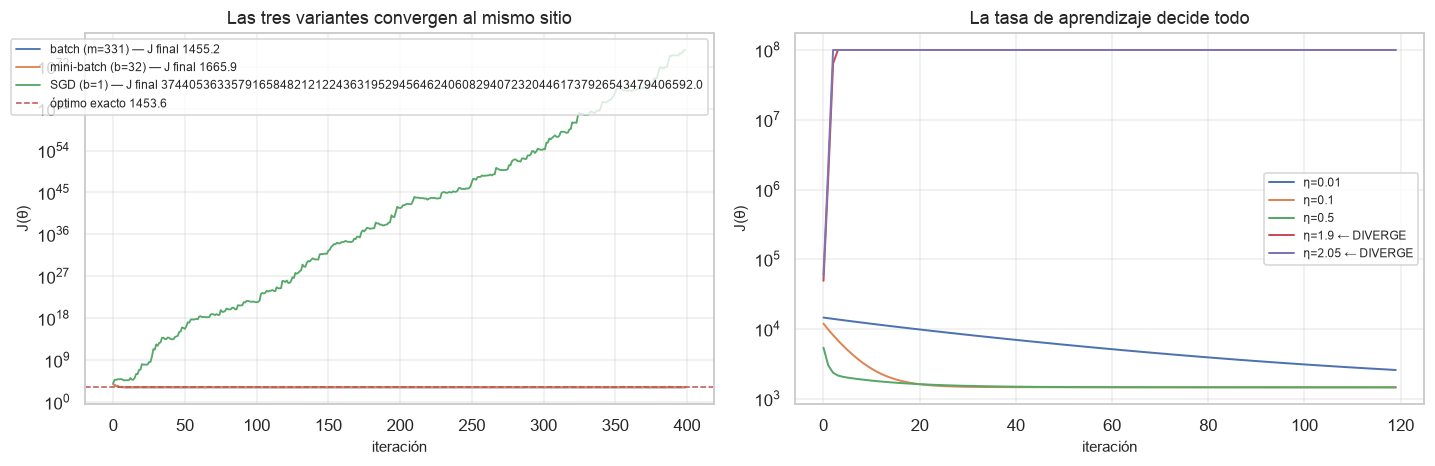


  Dos lecturas:

  · Las tres variantes llegan al mismo óptimo; difieren en SUAVIDAD y en costo
    por paso. SGD hace 400 pasos baratísimos y queda cerca; batch hace 400
    pasos caros y queda más fino.
  · La tasa de aprendizaje tiene un umbral DURO: por encima de 2/λ_máx (con
    λ_máx el mayor autovalor de XᵀX/m) el método diverge. No es que converja
    lento: explota. Eso también lo viste en NB-03 §7.1.

  Umbral teórico de estabilidad: η < 2/λ_máx = 0.510


In [5]:
def gradiente_descendente(X, y, eta=0.1, n_iter=500, lote=None, seed=0):
    """Devuelve (θ, historial_de_costo). lote=None -> batch; lote=1 -> SGD."""
    rg = np.random.default_rng(seed)
    m, d = X.shape
    theta = np.zeros(d)
    hist = []
    for it in range(n_iter):
        if lote is None:
            idx = slice(None)
            Xb, yb = X, y
        else:
            idx = rg.choice(m, size=min(lote, m), replace=False)
            Xb, yb = X[idx], y[idx]
        grad = Xb.T @ (Xb @ theta - yb) / len(yb)
        theta -= eta * grad
        hist.append(float(np.mean((X @ theta - y) ** 2) / 2))   # costo sobre TODO
    return theta, np.array(hist)


# Escalamos (obligatorio para el gradiente) y añadimos la columna de unos
esc = StandardScaler().fit(Xtr)
Xtr_s = np.column_stack([np.ones(len(Xtr)), esc.transform(Xtr)])
Xte_s = np.column_stack([np.ones(len(Xte)), esc.transform(Xte)])

theta_exacto = ajustar_lstsq(Xtr_s, ytr)
J_min = float(np.mean((Xtr_s @ theta_exacto - ytr) ** 2) / 2)
print(f"Óptimo exacto (lstsq): J = {J_min:.2f}\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for nombre, lote in [("batch (m=331)", None), ("mini-batch (b=32)", 32), ("SGD (b=1)", 1)]:
    th, h = gradiente_descendente(Xtr_s, ytr, eta=0.3, n_iter=400, lote=lote)
    axes[0].plot(h, lw=1.2, label=f"{nombre} — J final {h[-1]:.1f}")
axes[0].axhline(J_min, ls="--", c="r", lw=1, label=f"óptimo exacto {J_min:.1f}")
axes[0].set(xlabel="iteración", ylabel="J(θ)", title="Las tres variantes convergen al mismo sitio")
axes[0].legend(fontsize=8); axes[0].set_yscale("log")

for eta in (0.01, 0.1, 0.5, 1.9, 2.05):
    _, h = gradiente_descendente(Xtr_s, ytr, eta=eta, n_iter=120)
    etiqueta = f"η={eta}" + (" ← DIVERGE" if h[-1] > h[0] else "")
    axes[1].plot(np.clip(h, 1e-1, 1e8), lw=1.3, label=etiqueta)
axes[1].set(xlabel="iteración", ylabel="J(θ)", yscale="log",
            title="La tasa de aprendizaje decide todo")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("""
  Dos lecturas:

  · Las tres variantes llegan al mismo óptimo; difieren en SUAVIDAD y en costo
    por paso. SGD hace 400 pasos baratísimos y queda cerca; batch hace 400
    pasos caros y queda más fino.
  · La tasa de aprendizaje tiene un umbral DURO: por encima de 2/λ_máx (con
    λ_máx el mayor autovalor de XᵀX/m) el método diverge. No es que converja
    lento: explota. Eso también lo viste en NB-03 §7.1.""")

lam_max = np.linalg.eigvalsh(Xtr_s.T @ Xtr_s / len(ytr)).max()
print(f"\n  Umbral teórico de estabilidad: η < 2/λ_máx = {2/lam_max:.3f}")

### 4.3 La superficie de costo, y por qué escalar le cambia la forma

Con **dos** parámetros ($\theta_0$ y $\theta_1$) el costo $J(\theta)$ se puede dibujar
entero. Vale la pena hacerlo una vez, porque explica de golpe tres cosas que de otro
modo se memorizan sueltas: por qué existe una tasa de aprendizaje máxima, por qué el
escalado importa tanto, y qué significa geométricamente el **número de condición** de
NB-03 §3.4.

Para mínimos cuadrados $J$ es un **paraboloide**, así que sus curvas de nivel son
**elipses**. Y la razón entre el eje largo y el corto de esas elipses es
$\sqrt{\kappa}$:

- Variables **escaladas** → elipses casi circulares → el gradiente apunta al mínimo →
  pocos pasos.
- Variables **sin escalar** → elipses muy alargadas → el gradiente apunta
  **perpendicular a la curva de nivel**, que en un valle estrecho **no** es hacia el
  mínimo → la trayectoria zigzaguea entre las paredes.

Esa es la explicación completa de por qué §4.2 dice que el gradiente exige escalar y
`lstsq` no.

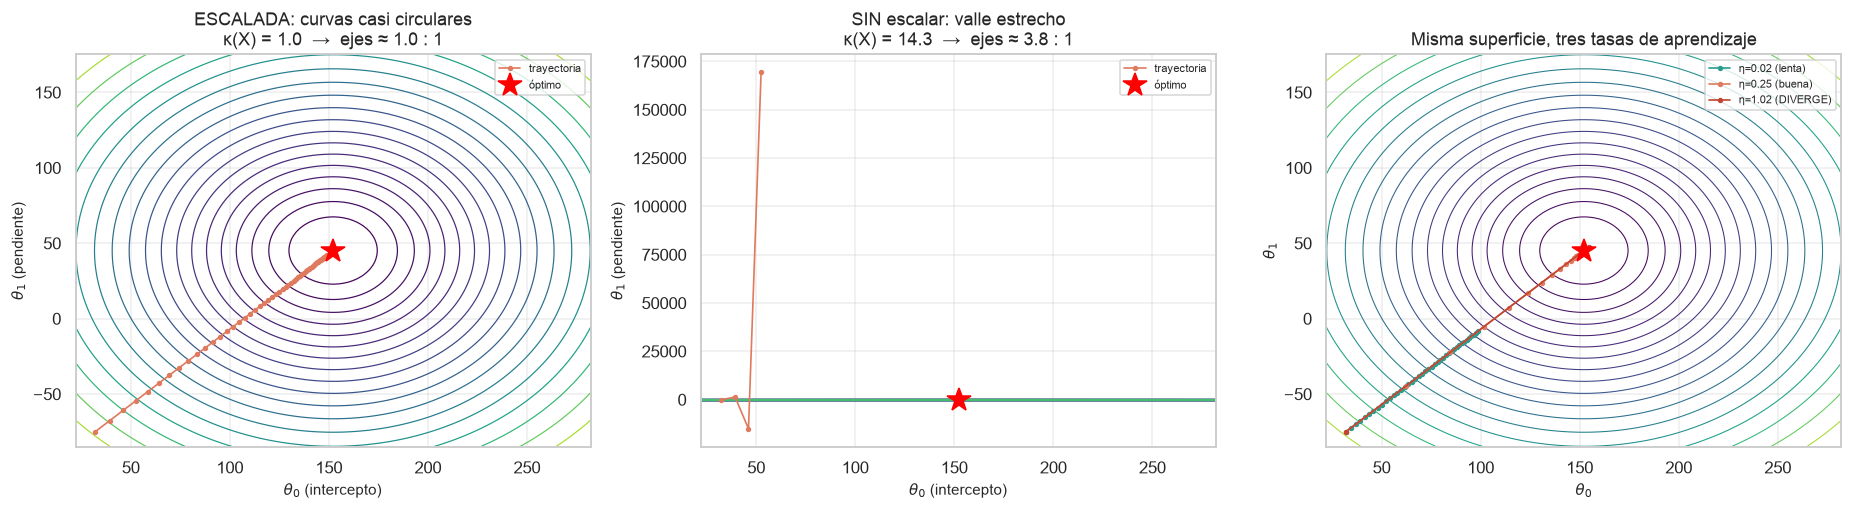

κ(X) sin escalar :      14.3  ->  ejes de la elipse ≈    3.8 : 1
κ(X) escalada    :       1.0  ->  ejes de la elipse ≈    1.0 : 1
Reducción de κ al escalar: ×14
  Lo que estás viendo es la explicación geométrica de todo el §4:

  · El gradiente siempre apunta PERPENDICULAR a la curva de nivel. En un
    círculo esa perpendicular apunta justo al centro; en una elipse alargada
    apunta contra la pared del valle, no al mínimo. De ahí el zigzag.
  · La razón entre los ejes de las elipses es √κ. Escalar reduce κ, redondea
    las elipses, y por eso el MISMO algoritmo converge en muchos menos pasos.
    No cambiaste el optimizador: cambiaste la forma del problema.
  · En el panel derecho, η = 1.02 salta al otro lado del valle en cada paso y
    se aleja. No es "converge lento": diverge. Ese es el umbral 2/λ_máx que
    calculaste arriba, ahora dibujado.


In [6]:
# Dos parámetros, para poder dibujar: intercepto + UNA variable (bmi)
x_una = X_dia["bmi"].to_numpy()
y_una = y_dia.to_numpy()

def superficie(x, y, r0, r1, n=120):
    T0, T1 = np.meshgrid(np.linspace(*r0, n), np.linspace(*r1, n))
    # J para cada par (θ0, θ1), vectorizado sobre la malla
    J = np.mean((T0[..., None] + T1[..., None] * x - y) ** 2, axis=-1) / 2
    return T0, T1, J

def gd_2d(x, y, eta, n_iter=60, inicio=(0.0, 0.0)):
    # Guarda la TRAYECTORIA completa, que es lo que queremos dibujar.
    t = np.array(inicio, dtype=float)
    camino = [t.copy()]
    for _ in range(n_iter):
        err = t[0] + t[1] * x - y
        t = t - eta * np.array([err.mean(), (err * x).mean()])
        camino.append(t.copy())
    return np.array(camino)

x_esc = (x_una - x_una.mean()) / x_una.std()
x_sin = x_una * 300.0                       # misma info, otras unidades

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for ax, xx, titulo in [(axes[0], x_esc, "ESCALADA: curvas casi circulares"),
                       (axes[1], x_sin, "SIN escalar: valle estrecho")]:
    X2 = np.column_stack([np.ones(len(xx)), xx])
    opt = ajustar_lstsq(X2, y_una)
    kappa = np.linalg.cond(X2)
    r0 = (opt[0] - 130, opt[0] + 130)
    r1 = (opt[1] - 130, opt[1] + 130)
    T0, T1, J = superficie(xx, y_una, r0, r1)
    ax.contour(T0, T1, J, levels=np.logspace(np.log10(J.min() + 1),
                                             np.log10(J.max()), 20),
               cmap="viridis", linewidths=.8)
    cam = gd_2d(xx, y_una, eta=0.06, n_iter=60, inicio=(opt[0] - 120, opt[1] - 120))
    cam = cam[np.all(np.isfinite(cam) & (np.abs(cam) < 1e6), axis=1)]
    ax.plot(cam[:, 0], cam[:, 1], "o-", c="#e07a5f", ms=2.5, lw=1.1, label="trayectoria")
    ax.plot(opt[0], opt[1], "*", c="red", ms=16, label="óptimo")
    ax.set(xlabel=r"$\theta_0$ (intercepto)", ylabel=r"$\theta_1$ (pendiente)",
           title=f"{titulo}\nκ(X) = {kappa:.1f}  →  ejes ≈ {np.sqrt(kappa):.1f} : 1")
    ax.legend(fontsize=7)

# Panel 3: la misma superficie, tres tasas de aprendizaje
X2 = np.column_stack([np.ones(len(x_esc)), x_esc])
opt = ajustar_lstsq(X2, y_una)
T0, T1, J = superficie(x_esc, y_una, (opt[0] - 130, opt[0] + 130),
                       (opt[1] - 130, opt[1] + 130))
axes[2].contour(T0, T1, J, levels=np.logspace(np.log10(J.min() + 1),
                                              np.log10(J.max()), 20),
                cmap="viridis", linewidths=.7)
for eta, color, nota in [(0.02, "#2a9d8f", " (lenta)"), (0.25, "#e07a5f", " (buena)"),
                         (1.02, "#c1452f", " (DIVERGE)")]:
    cam = gd_2d(x_esc, y_una, eta=eta, n_iter=40,
                inicio=(opt[0] - 120, opt[1] - 120))
    cam = cam[np.all(np.isfinite(cam) & (np.abs(cam) < 1e4), axis=1)]
    axes[2].plot(cam[:, 0], cam[:, 1], "o-", c=color, ms=2.5, lw=1.1,
                 label=f"η={eta}{nota}")
axes[2].plot(opt[0], opt[1], "*", c="red", ms=16)
axes[2].set(xlabel=r"$\theta_0$", ylabel=r"$\theta_1$",
            title="Misma superficie, tres tasas de aprendizaje")
axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

k_sin = np.linalg.cond(np.column_stack([np.ones(len(x_sin)), x_sin]))
k_esc = np.linalg.cond(np.column_stack([np.ones(len(x_esc)), x_esc]))
print(f"κ(X) sin escalar : {k_sin:9.1f}  ->  ejes de la elipse ≈ {np.sqrt(k_sin):6.1f} : 1")
print(f"κ(X) escalada    : {k_esc:9.1f}  ->  ejes de la elipse ≈ {np.sqrt(k_esc):6.1f} : 1")
print(f"Reducción de κ al escalar: ×{k_sin / k_esc:.0f}")
print("\n".join([
    "  Lo que estás viendo es la explicación geométrica de todo el §4:",
    "",
    "  · El gradiente siempre apunta PERPENDICULAR a la curva de nivel. En un",
    "    círculo esa perpendicular apunta justo al centro; en una elipse alargada",
    "    apunta contra la pared del valle, no al mínimo. De ahí el zigzag.",
    "  · La razón entre los ejes de las elipses es √κ. Escalar reduce κ, redondea",
    "    las elipses, y por eso el MISMO algoritmo converge en muchos menos pasos.",
    "    No cambiaste el optimizador: cambiaste la forma del problema.",
    "  · En el panel derecho, η = 1.02 salta al otro lado del valle en cada paso y",
    "    se aleja. No es \"converge lento\": diverge. Ese es el umbral 2/λ_máx que",
    "    calculaste arriba, ahora dibujado.",
]))

In [7]:
# El gradient checking de NB-03 §7.2, aplicado aquí. Es la prueba que hay que
# escribir SIEMPRE que derivas un gradiente a mano — y en NB-16 es obligatoria.
def grad_analitico(theta, X, y):
    return X.T @ (X @ theta - y) / len(y)

def grad_numerico(theta, X, y, h=1e-6):
    J = lambda t: np.mean((X @ t - y) ** 2) / 2
    g = np.zeros_like(theta)
    for i in range(len(theta)):
        tp, tm = theta.copy(), theta.copy()
        tp[i] += h; tm[i] -= h
        g[i] = (J(tp) - J(tm)) / (2 * h)          # diferencia CENTRADA: error O(h²)
    return g

th_prueba = rng.normal(size=Xtr_s.shape[1])
ga, gn = grad_analitico(th_prueba, Xtr_s, ytr), grad_numerico(th_prueba, Xtr_s, ytr)
err_rel = np.linalg.norm(ga - gn) / (np.linalg.norm(ga) + np.linalg.norm(gn))
print(f"Error relativo entre gradiente analítico y numérico: {err_rel:.2e}")
print(f"¿Pasa el check (< 1e-6)? {err_rel < 1e-6}")
print("""
  El criterio es el error RELATIVO, no el absoluto: con gradientes grandes una
  diferencia absoluta de 0.01 es despreciable, y con gradientes diminutos es
  catastrófica. Y se usa la diferencia CENTRADA porque su error es O(h²) en
  vez de O(h): con h=1e-6 eso son 12 dígitos en vez de 6.""")

Error relativo entre gradiente analítico y numérico: 1.03e-08
¿Pasa el check (< 1e-6)? True

  El criterio es el error RELATIVO, no el absoluto: con gradientes grandes una
  diferencia absoluta de 0.01 es despreciable, y con gradientes diminutos es
  catastrófica. Y se usa la diferencia CENTRADA porque su error es O(h²) en
  vez de O(h): con h=1e-6 eso son 12 dígitos en vez de 6.


---

## 5. El sobreajuste y las curvas de aprendizaje

### 5.1 Fabricando sobreajuste a propósito

La forma más limpia de ver el fenómeno es con **características polinomiales**: tomar
$x$ y generar $x, x^2, \ldots, x^p$. El modelo sigue siendo *lineal en los parámetros*
(por eso sirve aquí), pero su flexibilidad crece con $p$.

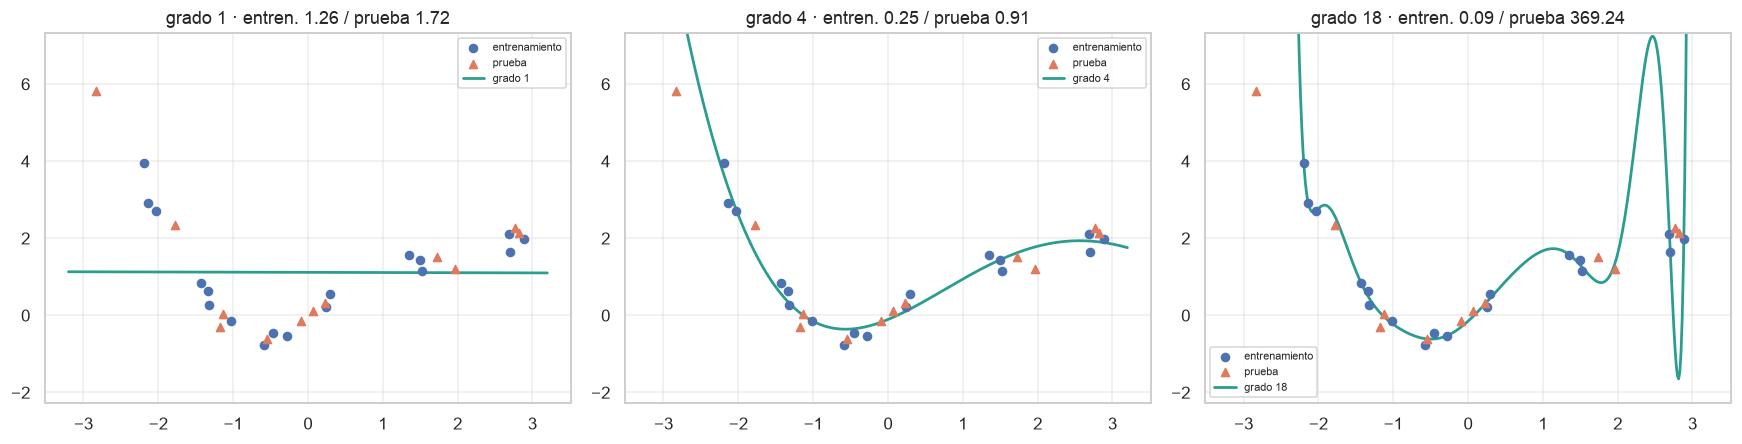

,grado,n° de parámetros,RMSE entren.,RMSE prueba
0,1,2,1.2617,1.7214
1,4,5,0.2484,0.9113
2,18,19,0.0936,369.2407



  Lee la tabla, no los dibujos:

  · grado 1  -> error alto en AMBOS. Es SUBAJUSTE (sesgo alto): el modelo es
               demasiado rígido para la forma real de los datos.
  · grado 4  -> error bajo en ambos y parecidos. Este es el punto bueno.
  · grado 18 -> error de entrenamiento casi cero y error de prueba DISPARADO.
               Es SOBREAJUSTE (varianza alta): memorizó el ruido.

  El síntoma de sobreajuste nunca es "el error es alto": es la BRECHA entre
  entrenamiento y prueba. Un modelo con 0.01 de error de entrenamiento y 3.0
  de prueba está peor que uno con 0.5 y 0.6.


In [8]:
# Datos de juguete: una curva suave + ruido. Pocos puntos, para que se note.
def generar_curva(n=30, ruido=0.25, seed=1):
    rg = np.random.default_rng(seed)
    x = np.sort(rg.uniform(-3, 3, n))
    y = 0.5 * x ** 2 - 0.3 * x + np.sin(1.6 * x) + ruido * rg.normal(size=n)
    return x.reshape(-1, 1), y

Xc, yc = generar_curva()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.4, random_state=SEED)
grid = np.linspace(-3.2, 3.2, 400).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
filas = []
for ax, p in zip(axes, (1, 4, 18)):
    modelo = make_pipeline(PolynomialFeatures(p), StandardScaler(), LinearRegression())
    modelo.fit(Xc_tr, yc_tr)
    rmse_tr = np.sqrt(mean_squared_error(yc_tr, modelo.predict(Xc_tr)))
    rmse_te = np.sqrt(mean_squared_error(yc_te, modelo.predict(Xc_te)))
    filas.append({"grado": p, "n° de parámetros": p + 1,
                  "RMSE entren.": rmse_tr, "RMSE prueba": rmse_te})
    ax.scatter(Xc_tr, yc_tr, s=28, label="entrenamiento", zorder=3)
    ax.scatter(Xc_te, yc_te, s=28, marker="^", c="#e07a5f", label="prueba", zorder=3)
    ax.plot(grid, modelo.predict(grid), c="#2a9d8f", lw=1.8, label=f"grado {p}")
    ax.set(ylim=(yc.min() - 1.5, yc.max() + 1.5),
           title=f"grado {p} · entren. {rmse_tr:.2f} / prueba {rmse_te:.2f}")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas))
print("""
  Lee la tabla, no los dibujos:

  · grado 1  -> error alto en AMBOS. Es SUBAJUSTE (sesgo alto): el modelo es
               demasiado rígido para la forma real de los datos.
  · grado 4  -> error bajo en ambos y parecidos. Este es el punto bueno.
  · grado 18 -> error de entrenamiento casi cero y error de prueba DISPARADO.
               Es SOBREAJUSTE (varianza alta): memorizó el ruido.

  El síntoma de sobreajuste nunca es "el error es alto": es la BRECHA entre
  entrenamiento y prueba. Un modelo con 0.01 de error de entrenamiento y 3.0
  de prueba está peor que uno con 0.5 y 0.6.""")

### 5.2 Curvas de aprendizaje: el diagnóstico que dice qué hacer

Saber que hay sobreajuste no basta; hay que saber **qué hacer**. La curva de
aprendizaje —error en función del **tamaño de la muestra**— responde justamente eso:

```
SUBAJUSTE (sesgo alto)              SOBREAJUSTE (varianza alta)
error                               error
  │                                   │
  │╲____________  validación          │╲____________  validación
  │─────────────  entrenamiento       │        ╲___
  │  las dos se juntan ALTO           │ ________/      brecha GRANDE
  └──────────────► n                  └──────────────► n
                                        y la brecha se cierra despacio

→ más datos NO ayuda                → más datos SÍ ayuda
→ modelo más complejo               → o regularizar, o simplificar
  o mejores variables
```

Esta distinción vale dinero: si tienes sesgo alto, conseguir más datos es **tiempo
perdido**. Si tienes varianza alta, conseguir más datos es lo **más efectivo** que
puedes hacer.

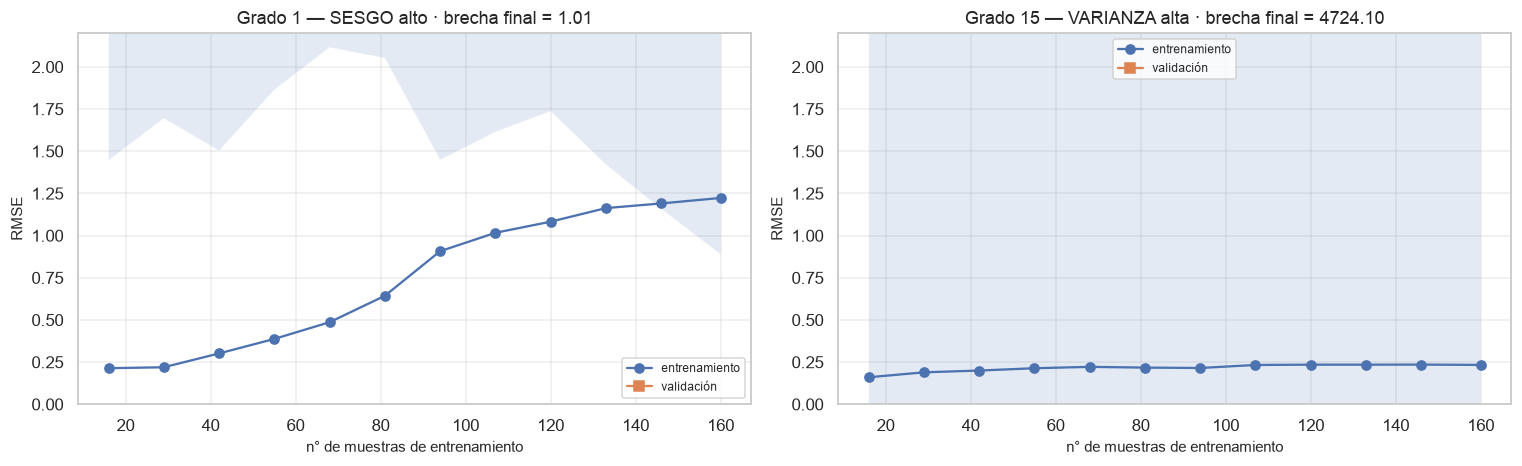


  Izquierda: las dos curvas se juntan y se quedan ALTAS. Darle más datos no
  mueve la aguja — el modelo no puede representar la curva, punto. Hay que
  cambiar el modelo.

  Derecha: la curva de entrenamiento está muy abajo y la de validación muy
  arriba, con una brecha que se va cerrando. Ahí sí: más datos ayudan, y
  regularizar ayuda ya mismo. Eso es lo que hacemos en la sección siguiente.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
Xg, yg = generar_curva(n=200, seed=3)
for ax, p, titulo in [(axes[0], 1, "Grado 1 — SESGO alto"),
                      (axes[1], 15, "Grado 15 — VARIANZA alta")]:
    modelo = make_pipeline(PolynomialFeatures(p), StandardScaler(), Ridge(alpha=1e-10))
    tam, sc_tr, sc_va = learning_curve(
        modelo, Xg, yg, cv=5, scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.1, 1.0, 12), random_state=SEED)
    ax.plot(tam, -sc_tr.mean(1), "o-", label="entrenamiento")
    ax.plot(tam, -sc_va.mean(1), "s-", label="validación")
    ax.fill_between(tam, -sc_va.mean(1) - sc_va.std(1), -sc_va.mean(1) + sc_va.std(1),
                    alpha=.15)
    brecha = (-sc_va.mean(1)[-1]) - (-sc_tr.mean(1)[-1])
    ax.set(xlabel="n° de muestras de entrenamiento", ylabel="RMSE",
           title=f"{titulo} · brecha final = {brecha:.2f}")
    ax.legend(fontsize=8)
axes[0].set_ylim(0, 2.2); axes[1].set_ylim(0, 2.2)
plt.tight_layout(); plt.show()
print("""
  Izquierda: las dos curvas se juntan y se quedan ALTAS. Darle más datos no
  mueve la aguja — el modelo no puede representar la curva, punto. Hay que
  cambiar el modelo.

  Derecha: la curva de entrenamiento está muy abajo y la de validación muy
  arriba, con una brecha que se va cerrando. Ahí sí: más datos ayudan, y
  regularizar ayuda ya mismo. Eso es lo que hacemos en la sección siguiente.""")

---

## 6. Regularización: Ridge, Lasso y Elastic Net

> **Esta sección es el "Regularización" del Control 4.** Es también la respuesta
> práctica al sobreajuste de §5.

### 6.1 La idea: penalizar la complejidad

En vez de elegir entre grado 4 y grado 18, **dejamos el modelo flexible y penalizamos
los coeficientes grandes**:

$$\min_\theta\;\|X\theta-y\|^2+\lambda\,\Omega(\theta)$$

| Nombre | $\Omega(\theta)$ | Efecto | Solución |
|---|---|---|---|
| **Ridge** (L2) | $\sum\theta_j^2=\|\theta\|_2^2$ | **encoge** todos hacia 0 | cerrada: $(X^\top X+\lambda I)^{-1}X^\top y$ |
| **Lasso** (L1) | $\sum\lvert\theta_j\rvert=\|\theta\|_1$ | **anula** algunos (selección) | iterativa (no derivable en 0) |
| **Elastic Net** | $\alpha\|\theta\|_1+\frac{1-\alpha}{2}\|\theta\|_2^2$ | mezcla ambos | iterativa |

Dos observaciones que se preguntan:

1. **El término independiente $\theta_0$ NO se penaliza.** Penalizarlo haría que el
   modelo no pudiera ajustar la media de $y$, lo que es absurdo: desplazar todos los
   datos en una constante cambiaría el modelo.
2. **Ridge es exactamente la regularización de Tíjonov de NB-03 §5.3.** La $\lambda I$
   que sumabas ahí para estabilizar la pseudoinversa **es** Ridge. Lo que allí era un
   truco numérico, aquí es una decisión estadística.

### 6.2 Por qué L1 produce ceros y L2 no — el argumento geométrico

Esta es **la** pregunta de la sección, y se responde con un dibujo, no con álgebra.

Minimizar el error sujeto a una restricción sobre $\theta$ equivale a hacer crecer las
elipses del error hasta que **tocan** la región permitida:

```
       RIDGE (L2): bola redonda          LASSO (L1): rombo con PUNTAS
            θ₂                                 θ₂
            │    ╱‾‾╲ elipses                  │    ╱‾‾╲
            │   ╱    ╲ del error               │   ╱    ╲
         ___│__╱______╲___                  ___│__╱______╲___
        ╱   │ ╲  ●toca ╱  ╲                    ╱│╲  ● toca  ╱
       │    │  ╲____╱     │                   ╱ │ ╲ EN LA PUNTA
        ╲___│___________╱                    ╱__│__╲______╱  θ₁
            │          θ₁                   ╲   │   ╱
                                             ╲  │  ╱
   El contacto ocurre en un punto             ╲ │ ╱
   GENÉRICO de la esfera:                      ╲│╱
   ningún coeficiente es 0.            La punta está SOBRE el eje θ₂,
                                       o sea θ₁ = 0 EXACTAMENTE.
```

**El argumento, en una frase:** la bola L2 es lisa, así que el punto de contacto casi
nunca cae sobre un eje; el rombo L1 tiene **vértices sobre los ejes**, y los vértices
atraen el contacto. Un vértice sobre el eje $\theta_2$ significa $\theta_1=0$ *exacto*,
no "muy pequeño".

Y en dimensión $d$ la cosa se acentúa: la bola L1 tiene $2d$ vértices y muchísimas
aristas de baja dimensión, todas ellas con coeficientes exactamente nulos.

In [10]:
# La demostración numérica: contamos ceros EXACTOS
Xp = PolynomialFeatures(12, include_bias=False).fit_transform(Xg)
Xp_s = StandardScaler().fit_transform(Xp)

filas = []
for nombre, modelo in [("sin regularizar", LinearRegression()),
                       ("Ridge  (L2, α=1)", Ridge(alpha=1.0)),
                       ("Ridge  (L2, α=100)", Ridge(alpha=100.0)),
                       ("Lasso  (L1, α=0.05)", Lasso(alpha=0.05, max_iter=50_000)),
                       ("Lasso  (L1, α=0.5)", Lasso(alpha=0.5, max_iter=50_000)),
                       ("ElasticNet (α=0.1, l1=0.5)",
                        ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50_000))]:
    modelo.fit(Xp_s, yg)
    c = modelo.coef_
    filas.append({"modelo": nombre,
                  "coef. EXACTAMENTE 0": int(np.sum(c == 0.0)),
                  "coef. |θ| < 1e-6": int(np.sum(np.abs(c) < 1e-6)),
                  "‖θ‖₁": float(np.abs(c).sum()), "‖θ‖₂": float(np.linalg.norm(c)),
                  "|θ| máximo": float(np.abs(c).max())})
display(pd.DataFrame(filas))
print(f"(12 características polinomiales)")
print("""
  Ahí está, en una columna: Lasso produce coeficientes EXACTAMENTE cero —no
  "casi cero", cero—, y Ridge produce exactamente ninguno por más que suba α.
  Ridge encoge (mira cómo baja ‖θ‖₂ y el máximo), pero nunca elimina.

  Consecuencia práctica, que es lo que hay que saber elegir:
  · Si quieres SELECCIONAR variables (quedarte con pocas, interpretables),
    Lasso lo hace solo.
  · Si tus variables están correlacionadas entre sí, Lasso elige UNA del grupo
    de forma arbitraria y descarta las demás. Ridge las reparte. Elastic Net
    existe justamente para ese caso: agrupa correlacionadas Y selecciona.""")

,modelo,coef. EXACTAMENTE 0,coef. |θ| < 1e-6,‖θ‖₁,‖θ‖₂,|θ| máximo
0,sin regularizar,0,0,104.3605,39.2376,22.8078
1,"Ridge (L2, α=1)",0,0,5.5200,2.4823,1.8164
2,"Ridge (L2, α=100)",0,0,1.6944,0.6611,0.4556
3,"Lasso (L1, α=0.05)",8,8,2.2549,1.3679,1.1728
4,"Lasso (L1, α=0.5)",10,10,0.9399,0.7528,0.7200
5,"ElasticNet (α=0.1, l1=0.5)",6,6,1.8884,1.0266,0.8543


(12 características polinomiales)

  Ahí está, en una columna: Lasso produce coeficientes EXACTAMENTE cero —no
  "casi cero", cero—, y Ridge produce exactamente ninguno por más que suba α.
  Ridge encoge (mira cómo baja ‖θ‖₂ y el máximo), pero nunca elimina.

  Consecuencia práctica, que es lo que hay que saber elegir:
  · Si quieres SELECCIONAR variables (quedarte con pocas, interpretables),
    Lasso lo hace solo.
  · Si tus variables están correlacionadas entre sí, Lasso elige UNA del grupo
    de forma arbitraria y descarta las demás. Ridge las reparte. Elastic Net
    existe justamente para ese caso: agrupa correlacionadas Y selecciona.


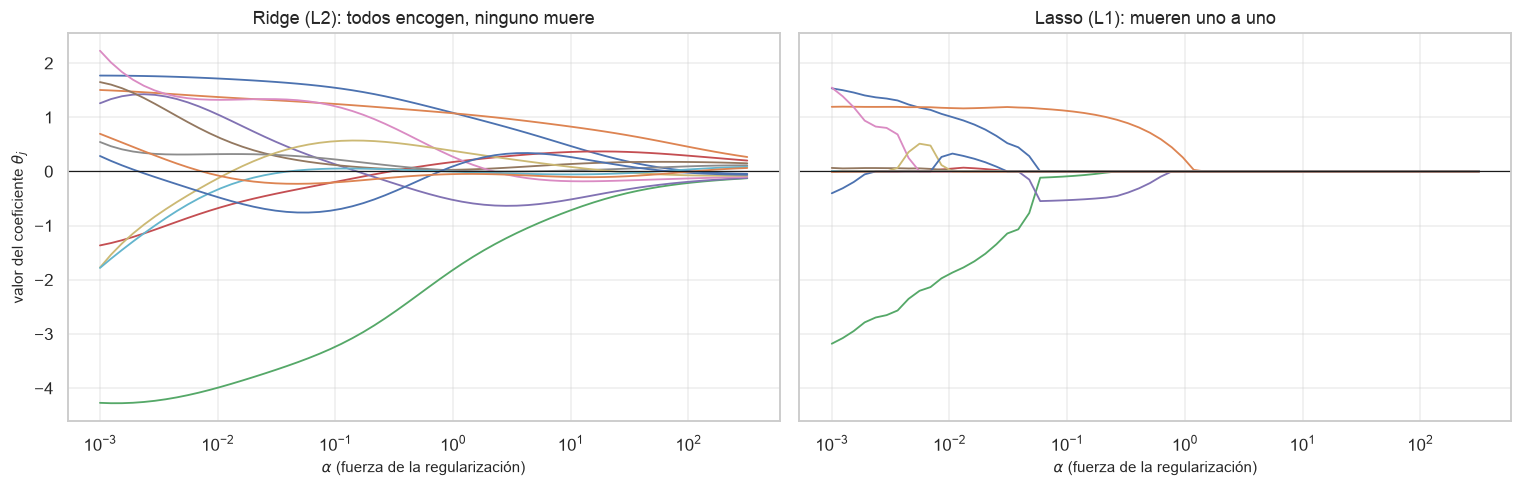

Coeficientes no nulos con α mínimo -> máximo:
   Ridge: 12 -> 12   (no muere ninguno)
   Lasso: 7 -> 0   (van muriendo)

  Este gráfico es la figura clásica del tema y se pregunta en pruebas. Lo que
  hay que poder describir con palabras:

  · α -> 0  : los dos convergen a la solución de mínimos cuadrados sin regularizar.
  · α -> ∞  : los dos llevan todos los coeficientes a 0 (modelo = la media).
  · En el medio: Ridge dibuja curvas SUAVES que se acercan a 0 sin tocarlo;
    Lasso dibuja tramos rectos que TOCAN el cero y se quedan ahí.


In [11]:
# El CAMINO de regularización: cómo evoluciona cada coeficiente al mover α
alphas = np.logspace(-3, 2.5, 60)
coef_ridge = np.array([Ridge(alpha=a).fit(Xp_s, yg).coef_ for a in alphas])
coef_lasso = np.array([Lasso(alpha=a, max_iter=50_000).fit(Xp_s, yg).coef_
                       for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, C, titulo in [(axes[0], coef_ridge, "Ridge (L2): todos encogen, ninguno muere"),
                      (axes[1], coef_lasso, "Lasso (L1): mueren uno a uno")]:
    for j in range(C.shape[1]):
        ax.plot(alphas, C[:, j], lw=1.2)
    ax.set(xscale="log", xlabel=r"$\alpha$ (fuerza de la regularización)", title=titulo)
    ax.axhline(0, c="k", lw=.8)
axes[0].set_ylabel(r"valor del coeficiente $\theta_j$")
plt.tight_layout(); plt.show()

n_vivos_ridge = [(np.abs(c) > 1e-10).sum() for c in coef_ridge]
n_vivos_lasso = [(np.abs(c) > 1e-10).sum() for c in coef_lasso]
print(f"Coeficientes no nulos con α mínimo -> máximo:")
print(f"   Ridge: {n_vivos_ridge[0]} -> {n_vivos_ridge[-1]}   (no muere ninguno)")
print(f"   Lasso: {n_vivos_lasso[0]} -> {n_vivos_lasso[-1]}   (van muriendo)")
print("""
  Este gráfico es la figura clásica del tema y se pregunta en pruebas. Lo que
  hay que poder describir con palabras:

  · α -> 0  : los dos convergen a la solución de mínimos cuadrados sin regularizar.
  · α -> ∞  : los dos llevan todos los coeficientes a 0 (modelo = la media).
  · En el medio: Ridge dibuja curvas SUAVES que se acercan a 0 sin tocarlo;
    Lasso dibuja tramos rectos que TOCAN el cero y se quedan ahí.""")

### 6.3 Escalar no es opcional

> ⚠ **TRAMPA que invalida resultados.** La penalización $\lambda\sum\theta_j^2$ trata
> **todos los coeficientes por igual**. Pero si una variable está en milímetros y otra
> en kilómetros, sus coeficientes viven en escalas completamente distintas, y la
> penalización castiga arbitrariamente a la de unidades pequeñas (que necesita
> coeficiente grande).
>
> **Regla sin excepciones: regularización ⇒ escalado previo.** Y el escalado se ajusta
> **solo con los datos de entrenamiento** (§8).

In [12]:
# Demostración: la MISMA variable, cambiada de unidad, cambia el modelo
X_esc = X_dia.to_numpy().copy()
X_esc[:, 2] = X_esc[:, 2] * 1000.0          # 'bmi' en otras unidades

filas = []
for nombre, Xuso in [("unidades originales", X_dia.to_numpy()),
                     ("una variable ×1000", X_esc)]:
    for escalar in (False, True):
        pasos = ([("esc", StandardScaler())] if escalar else []) + [("m", Ridge(alpha=1.0))]
        mod = Pipeline(pasos)
        sc = cross_val_score(mod, Xuso, y_dia.to_numpy(), cv=5,
                             scoring="neg_root_mean_squared_error")
        mod.fit(Xuso, y_dia.to_numpy())
        filas.append({"datos": nombre, "¿escalado?": "sí" if escalar else "NO",
                      "RMSE (CV)": -sc.mean(),
                      "|θ| de la variable tocada": abs(mod.named_steps["m"].coef_[2])})
display(pd.DataFrame(filas))
print("""
  Mira las dos filas SIN escalar: la misma información, en otras unidades, da
  un RMSE distinto. Eso es inaceptable — un modelo no puede depender de si
  mides en metros o en centímetros.

  Las dos filas CON escalado dan el mismo RMSE, como debe ser. El escalado no
  es un retoque de rendimiento: es lo que hace que el modelo sea una función de
  los DATOS y no de las UNIDADES.""")

,datos,¿escalado?,RMSE (CV),|θ| de la variable tocada
0,unidades originales,NO,58.4492,306.3527
1,unidades originales,sí,54.6989,24.7712
2,una variable ×1000,NO,56.8590,0.7048
3,una variable ×1000,sí,54.6989,24.7712



  Mira las dos filas SIN escalar: la misma información, en otras unidades, da
  un RMSE distinto. Eso es inaceptable — un modelo no puede depender de si
  mides en metros o en centímetros.

  Las dos filas CON escalado dan el mismo RMSE, como debe ser. El escalado no
  es un retoque de rendimiento: es lo que hace que el modelo sea una función de
  los DATOS y no de las UNIDADES.


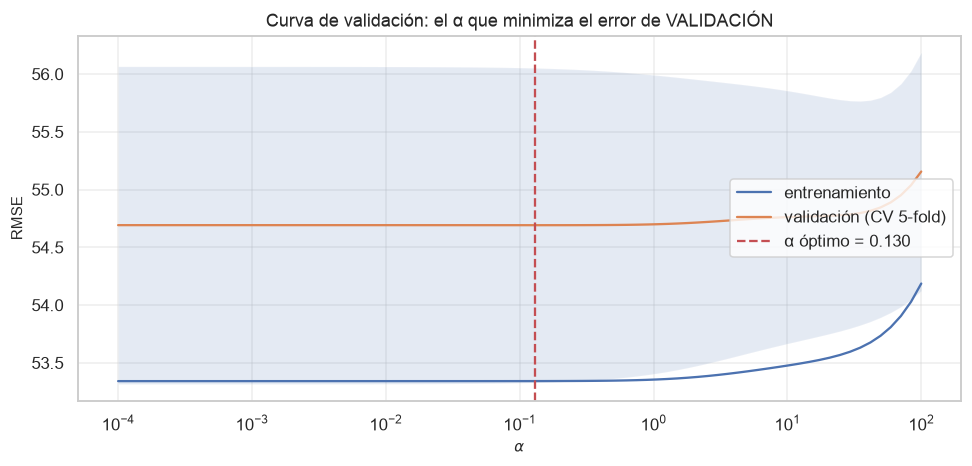

,modelo,RMSE entren.,RMSE prueba,R² entren.,R² prueba
0,lineal,53.9190,53.3696,0.5190,0.4849
1,RidgeCV (α=29.400),54.2366,53.0714,0.5134,0.4906
2,LassoCV (α=0.109),53.9468,53.2744,0.5185,0.4867


Lasso conservó 9 de 10 variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']

  Nota honesta sobre estos números: en 'diabetes' la regularización mejora
  POCO, porque con 442 muestras y 10 variables el modelo lineal casi no
  sobreajusta. Eso no invalida la técnica: muestra que la regularización
  sirve cuando hay MUCHOS parámetros respecto a los datos. En el §12 Nivel 2
  lo verás en un caso donde la diferencia es enorme.

  Lo que sí vale siempre: Lasso te dejó un modelo con menos variables y
  prácticamente el mismo error. Eso es un modelo más fácil de defender.


In [13]:
# Elegir α con validación cruzada, que es la única forma defendible
alphas_cv = np.logspace(-4, 2, 80)

fig, ax = plt.subplots(figsize=(9, 4.4))
tr_sc, va_sc = validation_curve(
    make_pipeline(StandardScaler(), Ridge()), X_dia.to_numpy(), y_dia.to_numpy(),
    param_name="ridge__alpha", param_range=alphas_cv, cv=5,
    scoring="neg_root_mean_squared_error")
ax.plot(alphas_cv, -tr_sc.mean(1), label="entrenamiento")
ax.plot(alphas_cv, -va_sc.mean(1), label="validación (CV 5-fold)")
ax.fill_between(alphas_cv, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1),
                alpha=.15)
mejor = alphas_cv[np.argmin(-va_sc.mean(1))]
ax.axvline(mejor, ls="--", c="r", label=f"α óptimo = {mejor:.3f}")
ax.set(xscale="log", xlabel=r"$\alpha$", ylabel="RMSE",
       title="Curva de validación: el α que minimiza el error de VALIDACIÓN")
ax.legend(); plt.tight_layout(); plt.show()

ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_cv, cv=5)).fit(Xtr, ytr)
lasso_cv = make_pipeline(StandardScaler(),
                         LassoCV(alphas=alphas_cv, cv=5, max_iter=50_000,
                                 random_state=SEED)).fit(Xtr, ytr)
filas = [reporte("lineal", ytr, lin.predict(Xtr), yte, lin.predict(Xte)),
         reporte(f"RidgeCV (α={ridge_cv[-1].alpha_:.3f})", ytr, ridge_cv.predict(Xtr),
                 yte, ridge_cv.predict(Xte)),
         reporte(f"LassoCV (α={lasso_cv[-1].alpha_:.3f})", ytr, lasso_cv.predict(Xtr),
                 yte, lasso_cv.predict(Xte))]
display(pd.DataFrame(filas))
nz = int((lasso_cv[-1].coef_ != 0).sum())
print(f"Lasso conservó {nz} de {Xtr.shape[1]} variables: "
      f"{[c for c, v in zip(X_dia.columns, lasso_cv[-1].coef_) if v != 0]}")
print("""
  Nota honesta sobre estos números: en 'diabetes' la regularización mejora
  POCO, porque con 442 muestras y 10 variables el modelo lineal casi no
  sobreajusta. Eso no invalida la técnica: muestra que la regularización
  sirve cuando hay MUCHOS parámetros respecto a los datos. En el §12 Nivel 2
  lo verás en un caso donde la diferencia es enorme.

  Lo que sí vale siempre: Lasso te dejó un modelo con menos variables y
  prácticamente el mismo error. Eso es un modelo más fácil de defender.""")

---

## 7. Regresión logística

### 7.1 De la regresión a la clasificación

Queremos predecir una **clase** (0 o 1), no un número. La idea ingenua —ajustar una
recta y cortar en 0.5— falla por dos motivos: la recta devuelve valores fuera de
$[0,1]$, y un punto muy alejado arrastra la frontera aunque esté bien clasificado.

La solución es pasar la salida lineal por la **sigmoide**:

$$p = \sigma(z) = \frac{1}{1+e^{-z}},\qquad z = x^\top\theta$$

que comprime $\mathbb{R}$ a $(0,1)$. Invirtiéndola aparece la interpretación que hay
que saber:

$$z = \log\frac{p}{1-p} \qquad \text{(el \emph{log-odds} o \emph{logit})}$$

> **O sea: la regresión logística es una regresión lineal sobre el logaritmo de la
> razón de probabilidades.** Por eso un coeficiente $\theta_j$ se interpreta como
> "aumentar $x_j$ en una unidad multiplica las probabilidades a favor por
> $e^{\theta_j}$". Es la frase que te pueden pedir.

### 7.2 Por qué la pérdida es la entropía cruzada y no el MSE

$$J(\theta)=-\frac{1}{m}\sum_i \Big[y_i\log p_i+(1-y_i)\log(1-p_i)\Big]$$

Dos razones, y la segunda es la decisiva:

1. **Viene de la máxima verosimilitud** (el MLE del Control 2): maximizar la
   probabilidad de los datos bajo un modelo de Bernoulli es exactamente minimizar esto.
2. **Con MSE, el problema deja de ser convexo.** $\text{MSE}(\sigma(x^\top\theta))$
   tiene mínimos locales; la entropía cruzada compuesta con la sigmoide es convexa, así
   que el gradiente **siempre** llega al óptimo global. Lo demostramos abajo midiendo.

Y un detalle elegante: el gradiente queda **idéntico** al de la regresión lineal,

$$\nabla J = \frac{1}{m}X^\top(\sigma(X\theta)-y)$$

o sea `Xᵀ(predicción − real)/m` en ambos casos. No es casualidad: las dos son modelos
lineales generalizados y comparten esa forma.

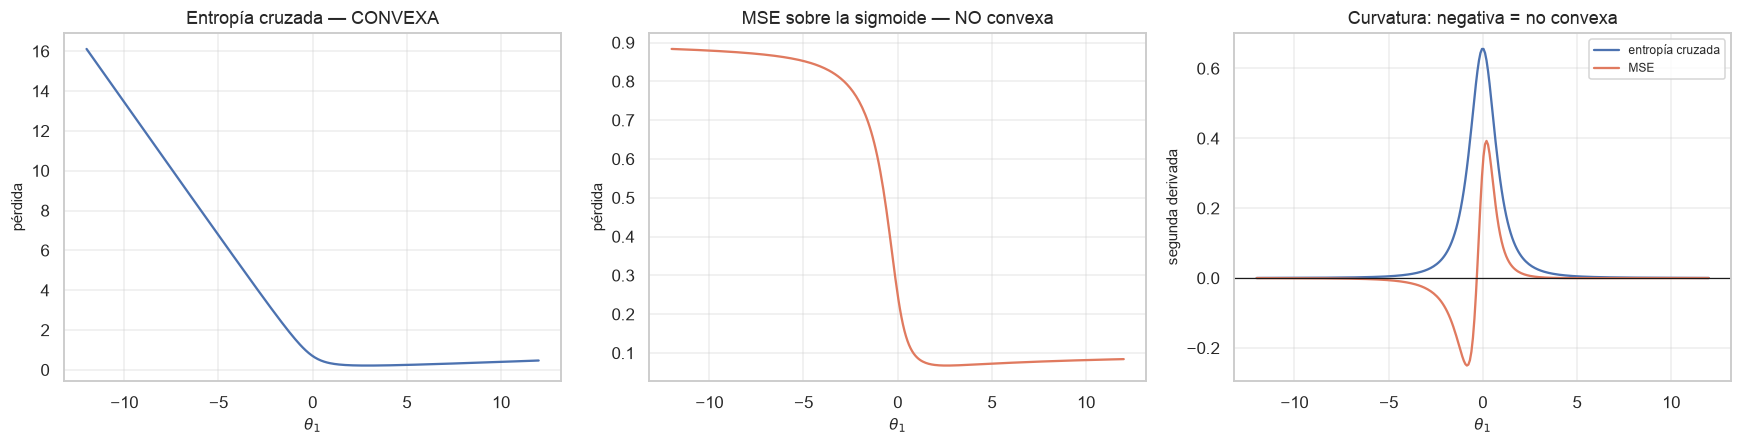

Mínimo de la 2ª derivada — entropía cruzada: +0.00019
Mínimo de la 2ª derivada — MSE             : -0.25057

  Ahí está la demostración numérica: la segunda derivada de la entropía cruzada
  nunca baja de 0 (convexa, salvo ruido de la derivación numérica), y la del
  MSE SÍ se vuelve claramente negativa (no convexa).

  ⚠ UN DETALLE QUE IMPORTA MÁS DE LO QUE PARECE. La primera versión de esta
  celda calculaba la entropía cruzada recortando p con np.clip para evitar
  log(0). Ese recorte aplana la curva en las colas, y una curva aplanada tiene
  curvatura negativa en el borde del recorte: el gráfico "demostraba" que la
  entropía cruzada NO era convexa, que es falso. Un arreglo numérico metido sin
  pensar puede destruir justo la propiedad que estás estudiando. Por eso aquí
  se usa logaddexp, que es exacto y no recorta nada.

  Por qué importa en la práctica: con una función convexa, cualquier óptimo
  local es el global y el descenso de gradiente tiene garantía de llegar. Con
  una n

In [14]:
sigmoide = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))   # clip: evita overflow

# Un problema 1-D para poder DIBUJAR la superficie de pérdida
rg = np.random.default_rng(0)
x1d = np.concatenate([rg.normal(-1.2, 1.0, 60), rg.normal(1.4, 1.0, 60)])
y1d = np.concatenate([np.zeros(60), np.ones(60)])
X1d = np.column_stack([np.ones(len(x1d)), x1d])

def perdida_ce(theta):
    """Entropía cruzada en su forma NUMÉRICAMENTE ESTABLE.

    La forma ingenua -mean(y·log p + (1-y)·log(1-p)) obliga a recortar p con
    np.clip para no evaluar log(0)... y ese recorte APLANA la curva en las
    colas, lo que mete curvatura negativa artificial y arruina justo la
    propiedad que queremos demostrar. La identidad
        -[y·log s(z) + (1-y)·log(1-s(z))] = log(1+e^z) - y*z
    se evalua con np.logaddexp sin desbordarse y sin recortar nada.
    """
    z = X1d @ theta
    return float(np.mean(np.logaddexp(0.0, z) - y1d * z))

def perdida_mse(theta):
    return np.mean((sigmoide(X1d @ theta) - y1d) ** 2)

w = np.linspace(-12, 12, 300)
ce = [perdida_ce(np.array([0.0, wi])) for wi in w]
ms = [perdida_mse(np.array([0.0, wi])) for wi in w]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(w, ce); axes[0].set(xlabel=r"$\theta_1$", ylabel="pérdida",
                                 title="Entropía cruzada — CONVEXA")
axes[1].plot(w, ms, c="#e07a5f"); axes[1].set(xlabel=r"$\theta_1$", ylabel="pérdida",
                                              title="MSE sobre la sigmoide — NO convexa")
# la curvatura lo prueba: la segunda derivada de la CE nunca cambia de signo
d2_ce = np.gradient(np.gradient(ce, w), w)
d2_ms = np.gradient(np.gradient(ms, w), w)
axes[2].plot(w, d2_ce, label="entropía cruzada")
axes[2].plot(w, d2_ms, c="#e07a5f", label="MSE")
axes[2].axhline(0, c="k", lw=.8)
axes[2].set(xlabel=r"$\theta_1$", ylabel="segunda derivada",
            title="Curvatura: negativa = no convexa"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Mínimo de la 2ª derivada — entropía cruzada: {np.min(d2_ce):+.5f}")
print(f"Mínimo de la 2ª derivada — MSE             : {np.min(d2_ms):+.5f}")
print("""
  Ahí está la demostración numérica: la segunda derivada de la entropía cruzada
  nunca baja de 0 (convexa, salvo ruido de la derivación numérica), y la del
  MSE SÍ se vuelve claramente negativa (no convexa).

  ⚠ UN DETALLE QUE IMPORTA MÁS DE LO QUE PARECE. La primera versión de esta
  celda calculaba la entropía cruzada recortando p con np.clip para evitar
  log(0). Ese recorte aplana la curva en las colas, y una curva aplanada tiene
  curvatura negativa en el borde del recorte: el gráfico "demostraba" que la
  entropía cruzada NO era convexa, que es falso. Un arreglo numérico metido sin
  pensar puede destruir justo la propiedad que estás estudiando. Por eso aquí
  se usa logaddexp, que es exacto y no recorta nada.

  Por qué importa en la práctica: con una función convexa, cualquier óptimo
  local es el global y el descenso de gradiente tiene garantía de llegar. Con
  una no convexa, el resultado depende de dónde arrancaste. Para un modelo de
  dos parámetros da casi igual; para una red neuronal, es la diferencia entre
  entrenar y no entrenar.""")

In [15]:
# Regresión logística sobre datos reales
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bc.to_numpy(), y_bc.to_numpy(),
                                              test_size=0.25, random_state=SEED,
                                              stratify=y_bc)
print(f"Entrenamiento {Xb_tr.shape} | prueba {Xb_te.shape} | "
      f"proporción de clase 1: {yb_tr.mean():.2f}")

log_sin = make_pipeline(StandardScaler(),
                        LogisticRegression(penalty=None, max_iter=5000)).fit(Xb_tr, yb_tr)
log_l2 = make_pipeline(StandardScaler(),
                       LogisticRegression(C=1.0, max_iter=5000)).fit(Xb_tr, yb_tr)
def logistica_l1(C):
    """L1 en logística, compatible con varias versiones de scikit-learn.

    Las versiones nuevas deprecaron penalty="l1" en favor de l1_ratio=1.0;
    las viejas no aceptan l1_ratio salvo con penalty="elasticnet". Probamos
    la API nueva y caemos a la antigua. Vale la pena el envoltorio: así el
    notebook corre igual en tu máquina y en la de un compañero.
    """
    try:
        return LogisticRegression(C=C, l1_ratio=1.0, solver="saga", max_iter=20_000)
    except TypeError:
        return LogisticRegression(C=C, penalty="l1", solver="liblinear", max_iter=5000)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")           # silencia el aviso de deprecación
    log_l1 = make_pipeline(StandardScaler(), logistica_l1(0.1)).fit(Xb_tr, yb_tr)

filas = []
for nombre, m in [("sin regularizar", log_sin), ("L2 (C=1)", log_l2),
                  ("L1 (C=0.1)", log_l1)]:
    ptr, pte = m.predict(Xb_tr), m.predict(Xb_te)
    coefs = m[-1].coef_.ravel()
    filas.append({"modelo": nombre,
                  "exactitud entren.": accuracy_score(yb_tr, ptr),
                  "exactitud prueba": accuracy_score(yb_te, pte),
                  "log-loss prueba": log_loss(yb_te, m.predict_proba(Xb_te)),
                  "variables usadas": int((np.abs(coefs) > 1e-8).sum()),
                  "‖θ‖₂": float(np.linalg.norm(coefs))})
display(pd.DataFrame(filas))
print("""
  ⚠ EL PARÁMETRO QUE CONFUNDE A TODO EL MUNDO: en scikit-learn, la regresión
  logística se regulariza con C, y C = 1/λ. O sea:

       C PEQUEÑO  ->  λ GRANDE  ->  MÁS regularización
       C GRANDE   ->  λ pequeño ->  MENOS regularización

  Es al revés que el alpha de Ridge y Lasso. Si en una prueba te preguntan qué
  pasa al "subir C", la respuesta es: regularizas MENOS y el modelo sobreajusta
  más. Equivocarse de dirección es el error más común del tema.""")

print("\nMatriz de confusión del modelo L2:")
cm = confusion_matrix(yb_te, log_l2.predict(Xb_te))
display(pd.DataFrame(cm, index=[f"real {n}" for n in bc.target_names],
                     columns=[f"pred. {n}" for n in bc.target_names]))
print("""  En un problema médico la matriz importa más que la exactitud: un falso
  negativo (decir 'benigno' a un maligno) y un falso positivo no cuestan lo
  mismo. Las métricas que capturan esa asimetría —precision, recall, F1— son
  NB-10.""")

Entrenamiento (426, 30) | prueba (143, 30) | proporción de clase 1: 0.63


,modelo,exactitud entren.,exactitud prueba,log-loss prueba,variables usadas,‖θ‖₂
0,sin regularizar,1.0000,0.958,1.0120,30,451.5585
1,L2 (C=1),0.9883,0.986,0.0679,30,3.5184
2,L1 (C=0.1),0.9742,0.965,0.1312,7,2.3769



  ⚠ EL PARÁMETRO QUE CONFUNDE A TODO EL MUNDO: en scikit-learn, la regresión
  logística se regulariza con C, y C = 1/λ. O sea:

       C PEQUEÑO  ->  λ GRANDE  ->  MÁS regularización
       C GRANDE   ->  λ pequeño ->  MENOS regularización

  Es al revés que el alpha de Ridge y Lasso. Si en una prueba te preguntan qué
  pasa al "subir C", la respuesta es: regularizas MENOS y el modelo sobreajusta
  más. Equivocarse de dirección es el error más común del tema.

Matriz de confusión del modelo L2:


,pred. malignant,pred. benign
real malignant,52,1
real benign,1,89


  En un problema médico la matriz importa más que la exactitud: un falso
  negativo (decir 'benigno' a un maligno) y un falso positivo no cuestan lo
  mismo. Las métricas que capturan esa asimetría —precision, recall, F1— son
  NB-10.


### 7.3 Más de dos clases: softmax

Con $K$ clases, la sigmoide se generaliza a **softmax**, que convierte $K$ puntajes en
una distribución de probabilidad:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}},\qquad z_k=x^\top\theta_k$$

Tres propiedades que hay que saber:

1. **Suma 1 y todo es positivo** por construcción: es una distribución, no "números
   que parecen probabilidades".
2. **Es invariante a sumar una constante** a todos los $z_k$. De ahí el truco de
   estabilidad numérica: restar $\max_k z_k$ antes de exponenciar evita el
   desbordamiento sin cambiar el resultado (lo mismo que `logaddexp` en §7.2).
3. Con $K=2$ **se reduce exactamente a la sigmoide**. Softmax no es otro modelo: es el
   mismo, escrito para $K$ clases.

La pérdida es la entropía cruzada categórica, $J=-\frac{1}{m}\sum_i\log p_{i,y_i}$:
castiga solo la probabilidad asignada a la clase **correcta**.

> **Softmax (multinomial) vs. uno-contra-resto (OvR).** OvR entrena $K$ clasificadores
> binarios independientes y normaliza después; softmax entrena **un** modelo conjunto
> cuyas probabilidades ya suman 1. Softmax suele estar mejor **calibrado** (sus
> probabilidades son más creíbles); OvR es más simple de paralelizar. Para una prueba:
> softmax modela las clases como **mutuamente excluyentes**, OvR no lo asume.

In [16]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
Xi, yi = iris.data.to_numpy(), iris.target.to_numpy()
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=.3,
                                              random_state=SEED, stratify=yi)
print(f"Iris: {Xi.shape} | {len(np.unique(yi))} clases: {[str(c) for c in iris.target_names]}")

def softmax_estable(Z):
    # exp(z - max) / Σ exp(z - max). El max NO cambia el resultado
    # (propiedad 2) pero evita que exp() desborde con puntajes grandes.
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

# Propiedad 2, verificada: sumar una constante no cambia nada
Z = rng.normal(size=(4, 3)) * 5
print(f"\n¿softmax(Z) == softmax(Z + 1000)? "
      f"{np.allclose(softmax_estable(Z), softmax_estable(Z + 1000))}")
print(f"¿La versión ingenua sobrevive a Z + 1000? ", end="")
with np.errstate(over="ignore", invalid="ignore"):
    ingenua = np.exp(Z + 1000) / np.exp(Z + 1000).sum(axis=1, keepdims=True)
print("sí" if np.all(np.isfinite(ingenua)) else "NO (desborda a nan)")

# Propiedad 3: con K=2, softmax == sigmoide
z = np.linspace(-6, 6, 7)
dos = softmax_estable(np.column_stack([np.zeros_like(z), z]))[:, 1]
print(f"¿softmax con K=2 coincide con la sigmoide? "
      f"{np.allclose(dos, 1 / (1 + np.exp(-z)))}")

# multinomial (softmax) vs uno-contra-resto
filas = []
for nombre, mod in [("softmax (multinomial)",
                     LogisticRegression(max_iter=5000)),
                    ("uno-contra-resto (OvR)",
                     OneVsRestClassifier(LogisticRegression(max_iter=5000)))]:
    pipe = make_pipeline(StandardScaler(), mod).fit(Xi_tr, yi_tr)
    P = pipe.predict_proba(Xi_te)
    filas.append({"estrategia": nombre,
                  "exactitud": accuracy_score(yi_te, pipe.predict(Xi_te)),
                  "log-loss": log_loss(yi_te, P),
                  "¿las probabilidades suman 1?": bool(np.allclose(P.sum(1), 1))})
display(pd.DataFrame(filas))

soft = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xi_tr, yi_tr)
P = soft.predict_proba(Xi_te[:5])
display(pd.DataFrame(P, columns=iris.target_names).assign(
    suma=P.sum(1), real=[iris.target_names[k] for k in yi_te[:5]]).round(4))
print("\n".join([
    "  Tres cosas confirmadas con código, no de palabra:",
    "",
    "  · Sumar 1000 a los puntajes no cambia la salida de softmax, pero SÍ rompe la",
    "    versión ingenua (desborda a nan). Por eso siempre se resta el máximo.",
    "  · Con K = 2, softmax es literalmente la sigmoide. No son dos modelos.",
    "  · Las dos estrategias aciertan parecido, pero OvR normaliza DESPUÉS de",
    "    entrenar K modelos sueltos, mientras softmax optimiza las K salidas a la",
    "    vez. Mira la log-loss, no la exactitud: ahí es donde se nota la diferencia",
    "    de calibración, porque la log-loss sí mira la probabilidad y no solo la",
    "    clase ganadora.",
    "",
    "  Esta es, además, la capa de salida de cualquier red neuronal de",
    "  clasificación: softmax + entropía cruzada categórica. NB-16 la reutiliza tal",
    "  cual.",
]))

Iris: (150, 4) | 3 clases: ['setosa', 'versicolor', 'virginica']

¿softmax(Z) == softmax(Z + 1000)? True
¿La versión ingenua sobrevive a Z + 1000? NO (desborda a nan)
¿softmax con K=2 coincide con la sigmoide? True


,estrategia,exactitud,log-loss,¿las probabilidades suman 1?
0,softmax (multinomial),0.9111,0.2096,True
1,uno-contra-resto (OvR),0.8444,0.3651,True


,setosa,versicolor,virginica,suma,real
0,0.0000,0.1014,0.8985,1.0,virginica
1,0.0141,0.7894,0.1964,1.0,versicolor
2,0.0036,0.6202,0.3762,1.0,virginica
3,0.0218,0.6292,0.3490,1.0,versicolor
4,0.0052,0.3846,0.6103,1.0,virginica


  Tres cosas confirmadas con código, no de palabra:

  · Sumar 1000 a los puntajes no cambia la salida de softmax, pero SÍ rompe la
    versión ingenua (desborda a nan). Por eso siempre se resta el máximo.
  · Con K = 2, softmax es literalmente la sigmoide. No son dos modelos.
  · Las dos estrategias aciertan parecido, pero OvR normaliza DESPUÉS de
    entrenar K modelos sueltos, mientras softmax optimiza las K salidas a la
    vez. Mira la log-loss, no la exactitud: ahí es donde se nota la diferencia
    de calibración, porque la log-loss sí mira la probabilidad y no solo la
    clase ganadora.

  Esta es, además, la capa de salida de cualquier red neuronal de
  clasificación: softmax + entropía cruzada categórica. NB-16 la reutiliza tal
  cual.


---

## 8. Validación cruzada y los tres errores que invalidan un experimento

### 8.1 Validación cruzada en k pliegues

Un único corte entrenamiento/prueba da una estimación **ruidosa**: cambias la semilla y
el resultado se mueve. La validación cruzada parte los datos en $k$ pliegues, entrena
$k$ veces dejando uno fuera cada vez, y promedia.

```
k = 5
pliegue:  [ 1 ][ 2 ][ 3 ][ 4 ][ 5 ]
ronda 1:  [VAL][ tr ][ tr ][ tr ][ tr ]
ronda 2:  [ tr ][VAL][ tr ][ tr ][ tr ]
   ...                                    → 5 estimaciones → media ± desviación
ronda 5:  [ tr ][ tr ][ tr ][ tr ][VAL]
```

**Siempre reporta la desviación, no solo la media.** Un 0.82 ± 0.01 y un 0.82 ± 0.09
son resultados muy distintos, y el segundo no permite afirmar casi nada — el mismo
argumento que usamos en NB-04 §15.3 con las corridas de SA y en NB-05 §12 con el
torneo.

### 8.2 Los tres errores

| Error | Qué pasa | Cómo se evita |
|---|---|---|
| **No escalar antes de regularizar** | la penalización castiga según las unidades | `Pipeline` con `StandardScaler` |
| **Fuga de datos** (*leakage*) | el escalador ve el test → el error estimado es optimista | ajustar **solo** con entrenamiento |
| **Elegir con el test** | el test deja de ser imparcial | elegir con **validación**, tocar el test una vez |

El segundo es el más traicionero porque **no produce ningún error visible**: tu modelo
"funciona mejor" y nadie se entera hasta producción.

In [17]:
# Demostración de FUGA DE DATOS. 400 variables (solo 10 informativas) y 120
# muestras: el escenario donde se ve de verdad.
#
# Las tres filas usan EXACTAMENTE el mismo modelo, el mismo escalado, la misma
# selección de 20 variables y la misma partición. Lo único que cambia es QUÉ
# PASO alcanzó a mirar las filas de prueba. Si cambiara algo más, estaríamos
# midiendo otra cosa — que es justo el error que tenía la primera versión de
# esta celda.
from sklearn.feature_selection import SelectKBest, f_regression

Xf, yf = make_regression(n_samples=120, n_features=400, n_informative=10,
                         noise=12.0, random_state=SEED)
PART = dict(test_size=0.3, random_state=SEED)      # la MISMA partición siempre
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

# --- C · correcto: partir primero, todo lo demás dentro del Pipeline ---
C_tr, C_te, yC_tr, yC_te = train_test_split(Xf, yf, **PART)
pipe_ok = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=20),
                        Ridge(alpha=1.0)).fit(C_tr, yC_tr)
rmse_C = rmse(yC_te, pipe_ok.predict(C_te))

# --- A · fuga SOLO en el escalado ---
X_esc_fuga = StandardScaler().fit_transform(Xf)                 # ← ve todo
A_tr, A_te, yA_tr, yA_te = train_test_split(X_esc_fuga, yf, **PART)
selA = SelectKBest(f_regression, k=20).fit(A_tr, yA_tr)         # correcto
mA = Ridge(alpha=1.0).fit(selA.transform(A_tr), yA_tr)
rmse_A = rmse(yA_te, mA.predict(selA.transform(A_te)))

# --- B · fuga SOLO en la selección de variables ---
X_sel_fuga = SelectKBest(f_regression, k=20).fit_transform(Xf, yf)   # ← ve todo
B_tr, B_te, yB_tr, yB_te = train_test_split(X_sel_fuga, yf, **PART)
escB = StandardScaler().fit(B_tr)                                # correcto
mB = Ridge(alpha=1.0).fit(escB.transform(B_tr), yB_tr)
rmse_B = rmse(yB_te, mB.predict(escB.transform(B_te)))

display(pd.DataFrame([
    {"procedimiento": "C · todo dentro del Pipeline (correcto)", "RMSE prueba": rmse_C,
     "optimismo aparente": 0.0},
    {"procedimiento": "A · fuga solo en el ESCALADO", "RMSE prueba": rmse_A,
     "optimismo aparente": rmse_C - rmse_A},
    {"procedimiento": "B · fuga solo en la SELECCIÓN", "RMSE prueba": rmse_B,
     "optimismo aparente": rmse_C - rmse_B}]))
print(f"""
  "Optimismo aparente" = cuánto MEJOR se ve el modelo de lo que realmente es.
  Positivo significa que la fuga te está regalando un número falso.

  · A, fuga en el escalado: {rmse_C - rmse_A:+.1f} sobre un RMSE de ~{rmse_C:.0f}, o sea
    del orden del {abs(rmse_C - rmse_A) / rmse_C:.0%}. StandardScaler solo "roba" la media y la
    desviación del conjunto completo; con 120 muestras eso casi no cambia nada.
    Es mala práctica, pero no es lo que arruina un informe.

  · B, fuga en la selección: {rmse_C - rmse_B:+.1f}, es decir un {abs(rmse_C - rmse_B) / rmse_C:.0%} de mejora
    REGALADA. Al elegir las 20 variables más correlacionadas con y usando
    también las filas de prueba, le dijiste al modelo dónde mirar. Y como 390
    de las 400 son ruido puro, siempre hay unas cuantas que por azar
    correlacionan con y EN ESTA MUESTRA: el modelo "acierta" sobre un patrón
    que no existe fuera de ella.

  La moraleja no es "el escalado da igual": es que la gravedad de una fuga es
  proporcional a CUÁNTO APRENDE de los datos el paso que se filtró. Escalar
  aprende 2 números por variable. Seleccionar aprende cuáles variables sirven,
  que es casi todo el modelo.

  Y lo peligroso es que B no lanza ningún error ni imprime advertencia alguna:
  el número que reportas simplemente se ve mejor. Por eso la regla no es "ten
  cuidado", es estructural: TODO lo que aprenda algo de los datos —escalar,
  imputar, SELECCIONAR, codificar— va DENTRO de un Pipeline. Así
  cross_val_score lo reajusta en cada pliegue y la fuga es imposible por
  construcción, no por disciplina.""")

# Y aquí sí se nota la regularización: 400 variables, 120 muestras (d >> m)
print(f"Datos: {Xf.shape[0]} muestras, {Xf.shape[1]} variables -> d >> m\n")
filas = []
for nombre, modelo in [
        ("lineal (sin regularizar)", make_pipeline(StandardScaler(), LinearRegression())),
        ("Ridge α=1",   make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
        ("Ridge α=100", make_pipeline(StandardScaler(), Ridge(alpha=100.0))),
        ("Lasso α=1",   make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=50_000))),
        ("ElasticNet",  make_pipeline(StandardScaler(),
                                      ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=50_000)))]:
    sc = cross_val_score(modelo, Xf, yf, cv=KFold(5, shuffle=True, random_state=SEED),
                         scoring="neg_root_mean_squared_error")
    modelo.fit(Xf, yf)
    c = modelo[-1].coef_
    filas.append({"modelo": nombre, "RMSE (CV)": -sc.mean(), "±": sc.std(),
                  "variables usadas": int((np.abs(c) > 1e-8).sum())})
res = pd.DataFrame(filas)
display(res)
peor, mejor_f = res["RMSE (CV)"].max(), res["RMSE (CV)"].min()
print(f"Mejora de la mejor regularización sobre el modelo sin regularizar: "
      f"{1 - mejor_f / peor:.0%}")
print("""
  ESTE es el caso donde la regularización no es un detalle. Con 400 variables
  y 120 muestras, el modelo sin regularizar puede ajustar el entrenamiento
  PERFECTAMENTE (hay más parámetros que ecuaciones) y no generaliza nada.

  Y fíjate en la última columna: Lasso se queda con un puñado de variables de
  las 400. Como el generador puso solo 10 informativas, Lasso está haciendo
  exactamente lo que debe — y ese es un argumento verificable, no una
  impresión.""")

,procedimiento,RMSE prueba,optimismo aparente
0,C · todo dentro del Pipeline (correcto),47.2855,0.0000
1,A · fuga solo en el ESCALADO,47.4784,-0.1929
2,B · fuga solo en la SELECCIÓN,39.5684,7.7170



  "Optimismo aparente" = cuánto MEJOR se ve el modelo de lo que realmente es.
  Positivo significa que la fuga te está regalando un número falso.

  · A, fuga en el escalado: -0.2 sobre un RMSE de ~47, o sea
    del orden del 0%. StandardScaler solo "roba" la media y la
    desviación del conjunto completo; con 120 muestras eso casi no cambia nada.
    Es mala práctica, pero no es lo que arruina un informe.

  · B, fuga en la selección: +7.7, es decir un 16% de mejora
    REGALADA. Al elegir las 20 variables más correlacionadas con y usando
    también las filas de prueba, le dijiste al modelo dónde mirar. Y como 390
    de las 400 son ruido puro, siempre hay unas cuantas que por azar
    correlacionan con y EN ESTA MUESTRA: el modelo "acierta" sobre un patrón
    que no existe fuera de ella.

  La moraleja no es "el escalado da igual": es que la gravedad de una fuga es
  proporcional a CUÁNTO APRENDE de los datos el paso que se filtró. Escalar
  aprende 2 números por variable. Selecc

,modelo,RMSE (CV),±,variables usadas
0,lineal (sin regularizar),154.7605,9.3571,400
1,Ridge α=1,154.8037,9.3638,400
2,Ridge α=100,159.5281,9.6681,400
3,Lasso α=1,16.2315,1.1139,65
4,ElasticNet,154.3018,7.7848,344


Mejora de la mejor regularización sobre el modelo sin regularizar: 90%

  ESTE es el caso donde la regularización no es un detalle. Con 400 variables
  y 120 muestras, el modelo sin regularizar puede ajustar el entrenamiento
  PERFECTAMENTE (hay más parámetros que ecuaciones) y no generaliza nada.

  Y fíjate en la última columna: Lasso se queda con un puñado de variables de
  las 400. Como el generador puso solo 10 informativas, Lasso está haciendo
  exactamente lo que debe — y ese es un argumento verificable, no una
  impresión.


---

## 9. Tabla comparativa y árbol de decisión 🧠 *para memorizar antes del Control 4*

| Modelo | Penalización | ¿Anula coeficientes? | Solución cerrada | Úsalo cuando |
|---|---|---|---|---|
| Mínimos cuadrados | — | — | sí | $d \ll m$ y sin colinealidad |
| **Ridge** | $\lambda\|\theta\|_2^2$ | **no** | **sí** | variables correlacionadas; $d$ grande |
| **Lasso** | $\lambda\|\theta\|_1$ | **sí** | no | quieres **seleccionar** variables |
| **Elastic Net** | mezcla | sí | no | correlacionadas **y** quieres selección |
| **Logística** | L1/L2 vía `C` | según penalización | no | clasificación binaria |

### Árbol de decisión

```
¿El objetivo es un NÚMERO o una CLASE?
│
├── CLASE ──► REGRESIÓN LOGÍSTICA
│             · pérdida: entropía cruzada (convexa; el MSE no lo es)
│             · regularización con C = 1/λ   ← ojo con la dirección
│             · multiclase: softmax (multinomial) o uno-contra-resto
│
└── NÚMERO ──► ¿d (variables) comparado con m (muestras)?
               │
               ├── d ≪ m, bien condicionado ──► lstsq / LinearRegression
               │
               └── d grande, o colinealidad, o sobreajuste
                   │
                   ├── ¿quieres SELECCIONAR variables?
                   │   ├── sí, y no están correlacionadas ──► LASSO
                   │   └── sí, y SÍ están correlacionadas ──► ELASTIC NET
                   └── no, solo estabilizar ──────────────► RIDGE

Y SIEMPRE:  escalar dentro de un Pipeline  ·  elegir λ con validación cruzada
            ·  tocar el conjunto de prueba UNA sola vez
```

---

## 10. 📋 Cheat Sheet

### Fórmulas

```
Mínimos cuadrados   θ = (XᵀX)⁻¹Xᵀy        ← NO lo implementes así
                    np.linalg.lstsq(X, y)  ← sí

Ridge (cerrada)     θ = (XᵀX + λI)⁻¹Xᵀy   ← la λI de NB-03 §5.3
Gradiente del MSE   ∇J = Xᵀ(Xθ − y)/m
Gradiente logístico ∇J = Xᵀ(σ(Xθ) − y)/m  ← MISMA forma

Sigmoide            σ(z) = 1/(1+e⁻ᶻ)       logit: z = log(p/(1−p))
Entropía cruzada    J = −(1/m)Σ[y·log p + (1−y)·log(1−p)]

Sesgo–varianza      E[(y−f̂)²] = sesgo² + varianza + σ²
Condición           κ(XᵀX) = κ(X)²         ← por eso lstsq
```

### Las correspondencias que hay que tener claras

| Concepto | Nombre en scikit-learn | Dirección |
|---|---|---|
| $\lambda$ en Ridge/Lasso | `alpha` | ↑ alpha = **más** regularización |
| $\lambda$ en logística | `C` = $1/\lambda$ | ↑ C = **menos** regularización |
| mezcla L1/L2 | `l1_ratio` | 1 = Lasso puro, 0 = Ridge puro |

### Diagnóstico en tres pasos

```
1. ¿Error de entrenamiento ALTO?     -> SUBAJUSTE  -> modelo más complejo / mejores variables
2. ¿Brecha entren.–validación GRANDE? -> SOBREAJUSTE -> regularizar / más datos / simplificar
3. ¿Los dos bajos y juntos?           -> está bien   -> ahora sí, mide en el test (una vez)
```

### Trampas que cuestan puntos

- ⚠ Creer que **Ridge anula** coeficientes. Los encoge; **solo Lasso anula**.
- ⚠ Equivocar la dirección de **`C`** en logística.
- ⚠ **Regularizar sin escalar**: el resultado depende de las unidades.
- ⚠ **Penalizar el intercepto** $\theta_0$.
- ⚠ Usar **MSE** como pérdida de clasificación: deja de ser convexa.
- ⚠ Ajustar el escalador **antes** de partir: fuga de datos.
- ⚠ Elegir el hiperparámetro **mirando el test**: el test deja de medir nada.

---

## 11. Conexiones con el mundo real

**IA (CIT-2013), Control 4.** "Regularización" es §6 completa. Las "ANN" del mismo
control se construyen sobre §4: una red es una composición de transformaciones lineales
con no linealidades, y su entrenamiento es el mismo descenso de gradiente, con la regla
de la cadena encima (NB-16). Y la regresión logística **es** una red neuronal de una
sola capa con activación sigmoide — literalmente.

**Big Data (CIT-2309).** La fuga de datos de §8 es el error que convierte un pipeline
ETL→modelo en un generador de resultados falsos. Si en tu Entrega 2 calculas cualquier
estadística global (media, IDF, popularidad) **antes** de separar los datos de
evaluación, tienes fuga.

**Comunicaciones / Tesis.** El ecualizador FIR de NB-03 (Nivel 3) resuelve
$\min_w\|Yw-x\|^2$: es esta misma regresión. Cuando le sumaste `λI` para estabilizarlo,
estabas aplicando Ridge sin llamarlo así. Y elegir $L$, $d$ y $\lambda$ por validación
en vez de a ojo es exactamente §8.

**Limitaciones y honestidad.**

- Un modelo lineal solo captura relaciones lineales **en las variables que le das**. Los
  polinomios de §5 amplían eso a costa de explotar el número de parámetros.
- La regularización **no arregla datos malos**: si hay colinealidad extrema (§3.2), la
  información para separar dos efectos simplemente no está.
- La validación cruzada supone muestras **independientes**. Con series de tiempo hay que
  usar `TimeSeriesSplit`, porque barajar filtra el futuro hacia el pasado.
- Lasso con variables correlacionadas elige una del grupo **de forma inestable**:
  cambias la semilla y elige otra. No interpretes "Lasso eligió X" como "X es la causa".

---

## 12. Ejercicios progresivos

### Nivel 1 — Reproducir (guiado): Ridge desde cero

Implementa `ridge_cerrada(X, y, lam)` con la fórmula $(X^\top X+\lambda I)^{-1}X^\top y$,
**sin penalizar el intercepto**, y verifica contra `sklearn.linear_model.Ridge`. Luego
comprueba numéricamente que al crecer $\lambda$ la norma $\|\theta\|_2$ decrece de forma
monótona.

In [18]:
# Tu turno (Nivel 1)

#### ✅ Solución — Nivel 1

λ=  0.1  máx|mía − sklearn| = 1.329e-12
λ=  1.0  máx|mía − sklearn| = 1.648e-12
λ= 10.0  máx|mía − sklearn| = 2.451e-13


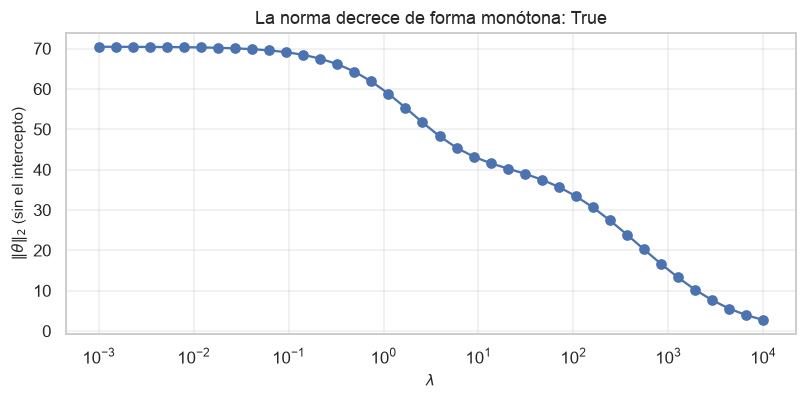

¿‖θ‖₂ decrece monótonamente al subir λ? True

  La monotonía no es casualidad: λ‖θ‖² es el precio de tener coeficientes
  grandes, y al subir el precio la solución óptima compra menos. Es la razón
  por la que λ se llama 'fuerza' de la regularización.

  Prueba a quitar el I[0,0] = 0 y vuelve a comparar con sklearn: vas a ver
  que el intercepto se desvía. Así se detecta ese bug.


In [19]:
def ridge_cerrada(X, y, lam):
    """(XᵀX + λI)⁻¹Xᵀy, SIN penalizar el intercepto.

    El truco de la primera fila/columna de I puesta a 0 es lo que implementa
    "no penalizar θ₀". Olvidarlo es el error clásico.
    """
    m, d = X.shape
    Xb = np.column_stack([np.ones(m), X])            # añadimos el intercepto
    I = np.eye(d + 1)
    I[0, 0] = 0.0                                    # ← el intercepto NO se penaliza
    return np.linalg.solve(Xb.T @ Xb + lam * I, Xb.T @ y)

Xs_tr = StandardScaler().fit_transform(Xtr)
for lam in (0.1, 1.0, 10.0):
    mia = ridge_cerrada(Xs_tr, ytr, lam)
    sk = Ridge(alpha=lam).fit(Xs_tr, ytr)
    sk_theta = np.concatenate([[sk.intercept_], sk.coef_])
    print(f"λ={lam:5.1f}  máx|mía − sklearn| = {np.abs(mia - sk_theta).max():.3e}")

lams = np.logspace(-3, 4, 40)
normas = [np.linalg.norm(ridge_cerrada(Xs_tr, ytr, l)[1:]) for l in lams]
monotona = all(normas[i] >= normas[i + 1] - 1e-9 for i in range(len(normas) - 1))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(lams, normas, "o-")
ax.set(xscale="log", xlabel=r"$\lambda$", ylabel=r"$\|\theta\|_2$ (sin el intercepto)",
       title=f"La norma decrece de forma monótona: {monotona}")
plt.tight_layout(); plt.show()
print(f"¿‖θ‖₂ decrece monótonamente al subir λ? {monotona}")
print("""
  La monotonía no es casualidad: λ‖θ‖² es el precio de tener coeficientes
  grandes, y al subir el precio la solución óptima compra menos. Es la razón
  por la que λ se llama 'fuerza' de la regularización.

  Prueba a quitar el I[0,0] = 0 y vuelve a comparar con sklearn: vas a ver
  que el intercepto se desvía. Así se detecta ese bug.""")

### Nivel 2 — Aplicar (problema nuevo): ¿dónde sí gana la regularización?

En §6.3 viste que en `diabetes` la regularización apenas mejora. Diseña un experimento
que **muestre dónde sí gana**: fija $m=120$ muestras y varía el número de variables $d$
de 10 a 400, comparando lineal, Ridge y Lasso con validación cruzada. Grafica el RMSE
frente a $d/m$ y localiza el punto donde la regularización empieza a ser decisiva.

In [20]:
# Tu turno (Nivel 2)

#### ✅ Solución — Nivel 2

,d,d/m,lineal,RidgeCV,LassoCV,ventaja de LassoCV
0,10,0.08,12.0362,12.0459,12.1094,1.0
1,30,0.25,15.2931,15.2951,13.5476,1.1
2,60,0.50,19.5141,19.5191,14.8925,1.3
3,90,0.75,52.9188,33.9367,11.5735,4.6
4,115,0.96,99.7314,103.6240,16.1195,6.2
5,150,1.25,125.9664,130.2883,15.7081,8.0
6,250,2.08,134.5447,142.4155,16.1908,8.3
7,400,3.33,154.7605,156.8879,16.7748,9.2


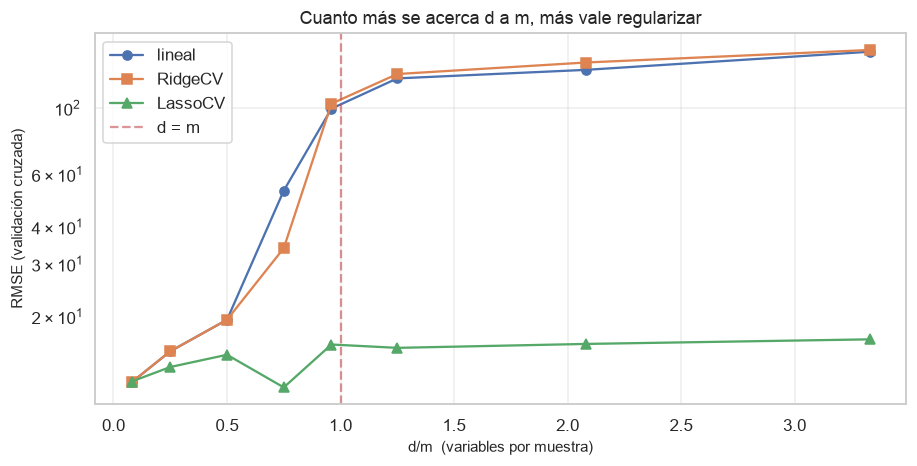


  Lo que muestran estos números, sin adornos:

  · Con d/m pequeño (d=10, d/m=0.08) los tres modelos están parejos:
    sobran datos para los parámetros que hay y no hay nada que regularizar.
  · La ventaja de regularizar crece de forma monótona con d/m. LassoCV pasa
    de empatar a ser ×9 mejor que el modelo sin regularizar en d=400.
  · El salto se vuelve claro a partir de d/m ≈ 0.75, donde el error del
    lineal ya dobla al del regularizado.

  Y una observación que hay que hacer, porque es la honesta: LassoCV gana por
  MUCHO más que RidgeCV, y no es casualidad ni mérito de L1 en abstracto. El
  generador puso solo 10 variables informativas entre 400, que es EXACTAMENTE
  el supuesto que Lasso explota (solución dispersa). Si las 400 aportaran un
  poco cada una, Ridge ganaría y Lasso sería el peor.

  O sea: la elección entre L1 y L2 no se hace probando, se hace a partir de lo
  que crees sobre tus datos. Probar solo confirma si creías bien.


In [21]:
M_FIJO = 120
ds = [10, 30, 60, 90, 115, 150, 250, 400]
ALPHAS = np.logspace(-2, 3, 25)
filas = []
for d in ds:
    Xd, yd = make_regression(n_samples=M_FIJO, n_features=d,
                             n_informative=min(10, d), noise=12.0, random_state=SEED)
    cv = KFold(5, shuffle=True, random_state=SEED)
    fila = {"d": d, "d/m": round(d / M_FIJO, 2)}
    # OJO: el alpha se elige por CV para CADA d. Dejarlo fijo sería hacer trampa
    # al revés: a distinta razón d/m le corresponde distinta fuerza óptima.
    for nombre, mod in [("lineal", LinearRegression()),
                        ("RidgeCV", RidgeCV(alphas=ALPHAS)),
                        ("LassoCV", LassoCV(alphas=ALPHAS, max_iter=20_000,
                                            random_state=SEED))]:
        sc = cross_val_score(make_pipeline(StandardScaler(), mod), Xd, yd, cv=cv,
                             scoring="neg_root_mean_squared_error")
        fila[nombre] = -sc.mean()
    filas.append(fila)
tab = pd.DataFrame(filas)
tab["ventaja de LassoCV"] = (tab["lineal"] / tab["LassoCV"]).round(1)
display(tab)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for nombre, estilo in [("lineal", "o-"), ("RidgeCV", "s-"), ("LassoCV", "^-")]:
    ax.plot(tab["d/m"], tab[nombre], estilo, label=nombre)
ax.axvline(1.0, ls="--", c="r", alpha=.6, label="d = m")
ax.set(xlabel="d/m  (variables por muestra)", ylabel="RMSE (validación cruzada)",
       yscale="log", title="Cuanto más se acerca d a m, más vale regularizar")
ax.legend(); plt.tight_layout(); plt.show()

primera = tab.loc[tab["ventaja de LassoCV"] >= 2.0].head(1)
print(f"""
  Lo que muestran estos números, sin adornos:

  · Con d/m pequeño (d={tab['d'].iloc[0]}, d/m={tab['d/m'].iloc[0]}) los tres modelos están parejos:
    sobran datos para los parámetros que hay y no hay nada que regularizar.
  · La ventaja de regularizar crece de forma monótona con d/m. LassoCV pasa
    de empatar a ser ×{tab['ventaja de LassoCV'].iloc[-1]:.0f} mejor que el modelo sin regularizar en d={tab['d'].iloc[-1]}.
  · El salto se vuelve claro a partir de d/m ≈ {primera['d/m'].iloc[0] if len(primera) else '—'}, donde el error del
    lineal ya dobla al del regularizado.

  Y una observación que hay que hacer, porque es la honesta: LassoCV gana por
  MUCHO más que RidgeCV, y no es casualidad ni mérito de L1 en abstracto. El
  generador puso solo 10 variables informativas entre 400, que es EXACTAMENTE
  el supuesto que Lasso explota (solución dispersa). Si las 400 aportaran un
  poco cada una, Ridge ganaría y Lasso sería el peor.

  O sea: la elección entre L1 y L2 no se hace probando, se hace a partir de lo
  que crees sobre tus datos. Probar solo confirma si creías bien.""")

### Nivel 3 — Integrar (NB-03 + NB-10 + Control 4): logística desde cero con regularización

Implementa la regresión logística completa **sin usar scikit-learn para ajustar**:

1. `perdida_y_grad(theta, X, y, lam)` que devuelva la entropía cruzada con penalización
   L2 (sin penalizar el intercepto) y su gradiente.
2. Verifícala con **gradient checking** (NB-03 §7.2).
3. Entrénala con descenso de gradiente y compara coeficientes y exactitud contra
   `LogisticRegression`.
4. Barre $\lambda$ y grafica exactitud de entrenamiento y validación: localiza el punto
   donde empieza el sobreajuste.

In [22]:
# Tu turno (Nivel 3)

#### ✅ Solución — Nivel 3

Gradient check: error relativo = 1.21e-10  ->  PASA

Mi implementación  : exactitud prueba = 0.9860
LogisticRegression : exactitud prueba = 0.9860
Correlación entre mis coeficientes y los de sklearn: 0.999853
Máxima diferencia absoluta entre coeficientes      : 0.0238


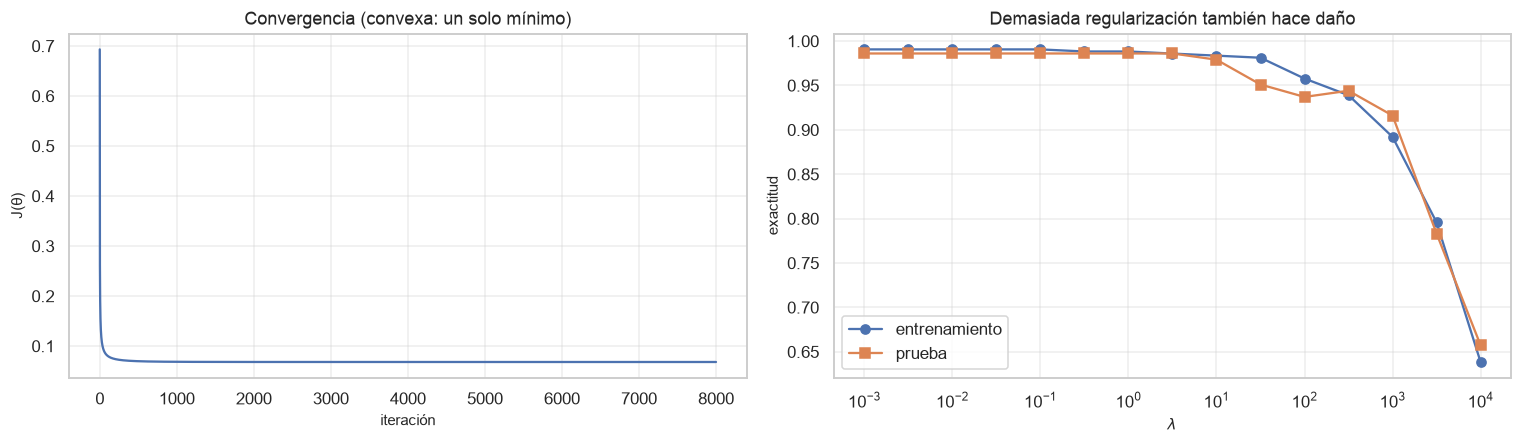


λ con mejor exactitud de prueba: 0.001  (exactitud 0.9860)
Con λ = 10000 (exceso de regularización): entren. 0.6385, prueba 0.6573

  Tres cosas que leer:

  · El gradient check pasa y los coeficientes coinciden con sklearn: la
    implementación es correcta, no "parecida". Si la correlación te sale baja,
    revisa el factor C = 1/λ antes que tu gradiente.

  · La tasa de aprendizaje no se adivina: sale de la cota de Lipschitz. Con
    λ = 10.000 y una eta fija de 0.5, este mismo código DIVERGE con overflow;
    con eta = 1/L converge para cualquier λ. Deducirla en vez de probarla es
    la diferencia entre un experimento y una sesión de prueba y error.

  · Las dos puntas de la curva derecha son las dos formas de equivocarse:
      λ muy pequeño -> entrenamiento alto, prueba más baja: SOBREAJUSTE.
      λ muy grande  -> las DOS bajan juntas: SUBAJUSTE inducido por regularizar
                       de más. El modelo ya no puede aprender.
    Por eso λ se elige con validación: tiene 

In [23]:
esc_bc = StandardScaler().fit(Xb_tr)
Atr = np.column_stack([np.ones(len(Xb_tr)), esc_bc.transform(Xb_tr)])
Ate = np.column_stack([np.ones(len(Xb_te)), esc_bc.transform(Xb_te)])

def perdida_y_grad(theta, X, y, lam=0.0):
    """Entropía cruzada + L2 (sin penalizar el intercepto), y su gradiente.

    Igual que en §7: la pérdida se evalúa con logaddexp, que es exacto y no
    necesita recortes. log(1+e^z) - y*z es la entropía cruzada.
    """
    m = len(y)
    z = X @ theta
    pen = theta.copy(); pen[0] = 0.0                     # el intercepto no se penaliza
    J = float(np.mean(np.logaddexp(0.0, z) - y * z) + (lam / (2 * m)) * pen @ pen)
    p = 1.0 / (1.0 + np.exp(-z))
    g = X.T @ (p - y) / m + (lam / m) * pen
    return J, g

# --- 2) gradient checking ---
th0 = rng.normal(scale=0.1, size=Atr.shape[1])
_, g_ana = perdida_y_grad(th0, Atr, yb_tr, lam=2.0)
g_num = np.zeros_like(th0)
for i in range(len(th0)):
    tp, tm = th0.copy(), th0.copy(); tp[i] += 1e-6; tm[i] -= 1e-6
    g_num[i] = (perdida_y_grad(tp, Atr, yb_tr, 2.0)[0]
                - perdida_y_grad(tm, Atr, yb_tr, 2.0)[0]) / 2e-6
err = np.linalg.norm(g_ana - g_num) / (np.linalg.norm(g_ana) + np.linalg.norm(g_num))
print(f"Gradient check: error relativo = {err:.2e}  ->  {'PASA' if err < 1e-6 else 'FALLA'}")

# --- 3) entrenamiento, con tasa de aprendizaje DEDUCIDA, no adivinada ---
def entrenar_logistica(X, y, lam=1.0, n_iter=8000, eta=None):
    """La cota de Lipschitz del gradiente da una eta segura automáticamente.

    Para la logística, la Hessiana es XᵀSX/m + (lam/m)I con S diagonal y
    S_ii = p(1-p) <= 1/4. Entonces L <= λmax(XᵀX)/(4m) + lam/m, y eta = 1/L
    garantiza convergencia sin probar valores a mano (ni divergir con lam grande).
    """
    m = len(y)
    if eta is None:
        L = np.linalg.eigvalsh(X.T @ X).max() / (4 * m) + lam / m
        eta = 1.0 / L
    th = np.zeros(X.shape[1]); hist = []
    for _ in range(n_iter):
        J, g = perdida_y_grad(th, X, y, lam)
        th -= eta * g; hist.append(J)
    return th, np.array(hist)

LAM = 1.0
th_mio, hist = entrenar_logistica(Atr, yb_tr, lam=LAM)
pred_mio = (1 / (1 + np.exp(-(Ate @ th_mio))) >= 0.5).astype(int)

# La correspondencia de escalas: mi penalización es (lam/2m)‖θ‖²; la de sklearn
# es (1/2)‖w‖² + C·Σ pérdidas, que dividida por C·m da (1/2Cm)‖w‖² + media.
# Igualando: lam/(2m) = 1/(2Cm)  ->  C = 1/lam.  (Equivocar este factor es el
# motivo habitual de que "mi implementación no coincide con sklearn".)
sk = LogisticRegression(C=1.0 / LAM, max_iter=10_000).fit(esc_bc.transform(Xb_tr), yb_tr)
print(f"\nMi implementación  : exactitud prueba = {accuracy_score(yb_te, pred_mio):.4f}")
print(f"LogisticRegression : exactitud prueba = "
      f"{accuracy_score(yb_te, sk.predict(esc_bc.transform(Xb_te))):.4f}")
corr = np.corrcoef(th_mio[1:], sk.coef_.ravel())[0, 1]
dif = np.abs(th_mio[1:] - sk.coef_.ravel()).max()
print(f"Correlación entre mis coeficientes y los de sklearn: {corr:.6f}")
print(f"Máxima diferencia absoluta entre coeficientes      : {dif:.4f}")

# --- 4) barrido de λ ---
lams = np.logspace(-3, 4, 15)
acc_tr, acc_te = [], []
for l in lams:
    th, _ = entrenar_logistica(Atr, yb_tr, lam=l, n_iter=4000)
    acc_tr.append(accuracy_score(yb_tr, (1 / (1 + np.exp(-(Atr @ th))) >= .5).astype(int)))
    acc_te.append(accuracy_score(yb_te, (1 / (1 + np.exp(-(Ate @ th))) >= .5).astype(int)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(hist); axes[0].set(xlabel="iteración", ylabel="J(θ)",
                                title="Convergencia (convexa: un solo mínimo)")
axes[1].plot(lams, acc_tr, "o-", label="entrenamiento")
axes[1].plot(lams, acc_te, "s-", label="prueba")
axes[1].set(xscale="log", xlabel=r"$\lambda$", ylabel="exactitud",
            title="Demasiada regularización también hace daño")
axes[1].legend(); plt.tight_layout(); plt.show()

mejor_lam = lams[int(np.argmax(acc_te))]
print(f"\nλ con mejor exactitud de prueba: {mejor_lam:.3f}  "
      f"(exactitud {max(acc_te):.4f})")
print(f"Con λ = {lams[-1]:.0f} (exceso de regularización): entren. {acc_tr[-1]:.4f}, "
      f"prueba {acc_te[-1]:.4f}")
print("""
  Tres cosas que leer:

  · El gradient check pasa y los coeficientes coinciden con sklearn: la
    implementación es correcta, no "parecida". Si la correlación te sale baja,
    revisa el factor C = 1/λ antes que tu gradiente.

  · La tasa de aprendizaje no se adivina: sale de la cota de Lipschitz. Con
    λ = 10.000 y una eta fija de 0.5, este mismo código DIVERGE con overflow;
    con eta = 1/L converge para cualquier λ. Deducirla en vez de probarla es
    la diferencia entre un experimento y una sesión de prueba y error.

  · Las dos puntas de la curva derecha son las dos formas de equivocarse:
      λ muy pequeño -> entrenamiento alto, prueba más baja: SOBREAJUSTE.
      λ muy grande  -> las DOS bajan juntas: SUBAJUSTE inducido por regularizar
                       de más. El modelo ya no puede aprender.
    Por eso λ se elige con validación: tiene un óptimo interior, no un extremo.""")

---

## 13. Resumen y siguiente paso

### Resumen en 7 líneas

1. Aprender no es ajustar: el objetivo es el error en datos **que no tienes**, y por eso
   hay que **estimarlo** (validación) y **controlarlo** (regularización).
2. El error se parte en **sesgo² + varianza + ruido**, y los dos primeros se mueven en
   direcciones opuestas con la complejidad.
3. Resuelve mínimos cuadrados con **`lstsq`**, nunca con $(X^\top X)^{-1}$: $\kappa$ se
   eleva al cuadrado.
4. El **descenso de gradiente** necesita escalado y una $\eta$ por debajo del umbral de
   estabilidad.
5. **Ridge encoge, Lasso anula.** La razón son los **vértices** de la bola L1 sobre los
   ejes.
6. La **logística** es una regresión lineal sobre el *log-odds*, con **entropía cruzada**
   como pérdida porque el MSE la vuelve no convexa. Y en sklearn, `C = 1/λ`.
7. Todo lo que aprenda de los datos va **dentro de un `Pipeline`**, o tienes fuga.

### Checklist antes del Control 4 (~9 nov)

Marca solo lo que puedas hacer **sin mirar el notebook**:

- [ ] Explicar el dibujo de la bola L1 vs. L2 y por qué L1 anula coeficientes.
- [ ] Escribir la pérdida de entropía cruzada y decir por qué no se usa el MSE.
- [ ] Decir qué le pasa al modelo si **subes** `C` en `LogisticRegression`.
- [ ] Distinguir subajuste de sobreajuste con una curva de aprendizaje.
- [ ] Decir por qué hay que escalar antes de regularizar (y no antes de `lstsq`).
- [ ] Explicar qué es la fuga de datos y dar un ejemplo que no produzca error.

### El hueco que queda para ese control

El Control 4 cubre **KNN, SVM, Regularización y ANN**. Este notebook cubre
**Regularización** por completo y deja el gradiente listo para las **ANN** (NB-16).
**KNN y SVM no están aquí** y no corresponden a ningún notebook de la serie que pueda
identificar: es un hueco de cobertura que conviene cerrar antes del 9 de noviembre.

### Siguiente paso

→ **NB-16 — Backpropagation**: una red neuronal es esta misma maquinaria, con capas
encadenadas y la regla de la cadena para propagar el gradiente hacia atrás. El
*gradient checking* de §4 deja de ser un ejercicio y se vuelve obligatorio.
En paralelo, **NB-10** (métricas de clasificación: precision, recall, F1, ROC) completa
lo que §7 dejó apenas insinuado con la matriz de confusión.

### Para profundizar

- Géron, *Hands-On ML*, cap. 4 — modelos lineales, gradiente, regularización, logística.
- Raschka, cap. 3 (logística y regularización) y cap. 4 (escalado y selección).
- Hastie, Tibshirani & Friedman, *ESL*, cap. 3.4 — la geometría de Ridge y Lasso.
- Tibshirani, R. (1996). *Regression Shrinkage and Selection via the Lasso* — el original.